In [ ]:
import pandas as pd

: 

# PCA Lab — see every claim from the README with your own eyes

This notebook is the hands-on companion to [`../README.md`](../README.md).
Every lab is **self-contained**: a short goal, the code, the picture/numbers, and a
**"How to read this"** box that tells you what you should notice.

**How to use it**

1. Run the first code cell (imports). After that you can run any lab in order (`Shift + Enter` cell by cell),
   or `Kernel → Restart & Run All`. Labs only reuse data from *earlier* labs, so running top-to-bottom always works.
2. Read the "How to read this" box *after* looking at the output — try to guess first.
3. Change the numbers marked `# <- try changing this` and re-run to build intuition.

| Part | Labs | What it proves |
|---|---|---|
| **[A. How PCA works](#part-a)** | [1](#lab-1), [2](#lab-2), [3](#lab-3), [4](#lab-4) | Covariance → eigenvectors → principal components, three different ways to compute the same thing |
| **[B. Why PCA is useful in ML](#part-b)** | [5](#lab-5), [6](#lab-6), [7](#lab-7), [8](#lab-8), [9](#lab-9) | Compression, visualisation, denoising, faster/smaller models with almost no accuracy loss |
| **[C. Where PCA fails (and why)](#part-c)** | [10](#lab-10), [11](#lab-11), [12](#lab-12) ([12b](#lab-12b)), [13](#lab-13), [14](#lab-14), [15](#lab-15) | Units, curved data, label info hiding in low variance, outliers, nothing-to-compress, mixed signals |
| **[D. Does PCA help this model?](#part-d)** | [16](#lab-16), [17](#lab-17) | Tree models (mostly no), clustering on high-dimensional data (mostly yes) |
| **[Summary](#summary)** | all | One-line verdict for every lab |
| **[Beyond the labs](#beyond-the-labs)** | — | Which models PCA helps, and which it hurts |

All datasets are either generated in the notebook or ship inside scikit-learn — **no internet needed**, except
Lab 17's Olivetti faces (about 1.4 MB) and Lab 16's California housing data (about 400 KB), which scikit-learn
downloads once and caches.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist

from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.covariance import MinCovDet
from sklearn.datasets import (fetch_california_housing, fetch_olivetti_faces, load_breast_cancer, load_diabetes,
                              load_digits, load_iris, load_wine, make_blobs, make_circles)
from sklearn.decomposition import PCA, FastICA, KernelPCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import (GradientBoostingClassifier, GradientBoostingRegressor, RandomForestClassifier,
                              RandomForestRegressor)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import adjusted_rand_score
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline, make_union
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})


def draw_arrow(ax, start, vector, color, label=None, lw=2.5):
    """Draw `vector` as an arrow starting at `start` on the matplotlib axes `ax`."""
    ax.annotate("", xy=np.asarray(start) + vector, xytext=start,
                arrowprops=dict(arrowstyle="->", color=color, lw=lw))
    if label:
        ax.plot([], [], color=color, lw=lw, label=label)  # invisible line, only for the legend


def angle_of(vector):
    """Direction of a 2-D vector in degrees, folded into [0, 180) because u and -u are the same axis."""
    return np.degrees(np.arctan2(vector[1], vector[0])) % 180

---

<a id="part-a"></a>

# Part A — How PCA works

<a id="lab-1"></a>

## Lab 1 · The hand-worked example, done by the computer

**Goal:** reproduce README section 5 (“A complete example by hand”) number by number:
4 points → mean → centred data → covariance matrix → eigenvalues/eigenvectors → new coordinates.

In [2]:
X_toy = np.array([[5, 7],
                  [1, 3],
                  [4, 4],
                  [2, 6]], dtype=float)          # 4 samples, 2 features

mean_toy = X_toy.mean(axis=0)
Xc_toy = X_toy - mean_toy                        # step 1: centre
S_toy = Xc_toy.T @ Xc_toy / len(X_toy)           # step 2: covariance (divide by n, like the README)

eigenvalues_toy, eigenvectors_toy = np.linalg.eigh(S_toy)   # step 3: eigen-decomposition
order = np.argsort(eigenvalues_toy)[::-1]                    # eigh returns smallest first -> flip
eigenvalues_toy, eigenvectors_toy = eigenvalues_toy[order], eigenvectors_toy[:, order]

scores_toy = Xc_toy @ eigenvectors_toy           # step 4: coordinates in the new (PC) axes

print("mean                 :", mean_toy)
print("centred data:\n", Xc_toy)
print("covariance matrix S:\n", S_toy)
print("eigenvalues          :", eigenvalues_toy)
print("eigenvectors (columns = PC1, PC2):\n", eigenvectors_toy)
print("scores (each row = one sample in PC coordinates):\n", scores_toy)
print("variance of each score column:", scores_toy.var(axis=0), "  <- equals the eigenvalues")
print("total variance before:", np.trace(S_toy), "  after:", scores_toy.var(axis=0).sum())
print("explained variance ratio:", eigenvalues_toy / eigenvalues_toy.sum())

mean                 : [3. 5.]
centred data:
 [[ 2.  2.]
 [-2. -2.]
 [ 1. -1.]
 [-1.  1.]]
covariance matrix S:
 [[2.5 1.5]
 [1.5 2.5]]
eigenvalues          : [4. 1.]
eigenvectors (columns = PC1, PC2):
 [[ 0.707 -0.707]
 [ 0.707  0.707]]
scores (each row = one sample in PC coordinates):
 [[ 2.828  0.   ]
 [-2.828  0.   ]
 [ 0.    -1.414]
 [ 0.     1.414]]
variance of each score column: [4. 1.]   <- equals the eigenvalues
total variance before: 5.0   after: 4.999999999999999
explained variance ratio: [0.8 0.2]


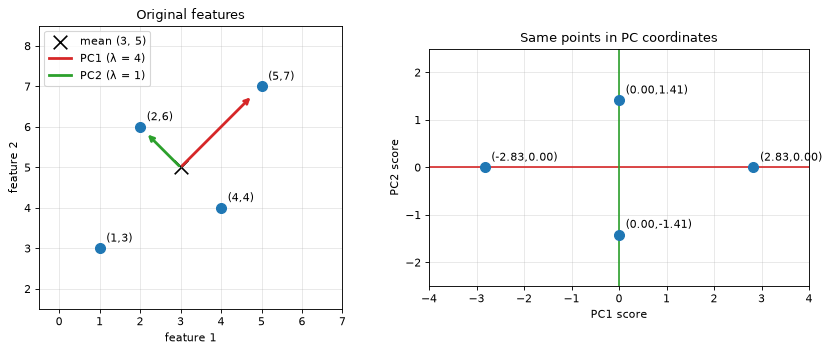

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

ax = axes[0]
ax.scatter(X_toy[:, 0], X_toy[:, 1], s=80, zorder=3)
for (x, y) in X_toy:
    ax.annotate(f"({x:.0f},{y:.0f})", (x, y), textcoords="offset points", xytext=(6, 6))
ax.scatter(*mean_toy, marker="x", s=150, color="black", label="mean (3, 5)")
draw_arrow(ax, mean_toy, 2.5 * eigenvectors_toy[:, 0], "tab:red", "PC1 (λ = 4)")
draw_arrow(ax, mean_toy, 1.2 * eigenvectors_toy[:, 1], "tab:green", "PC2 (λ = 1)")
ax.set_aspect("equal"); ax.set_xlim(-0.5, 7); ax.set_ylim(1.5, 8.5)
ax.set_title("Original features"); ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2"); ax.legend()

ax = axes[1]
ax.scatter(scores_toy[:, 0], scores_toy[:, 1], s=80, zorder=3)
for (z1, z2) in scores_toy:
    ax.annotate(f"({z1:.2f},{z2:.2f})", (z1, z2), textcoords="offset points", xytext=(6, 6))
ax.axhline(0, color="tab:red"); ax.axvline(0, color="tab:green")
ax.set_aspect("equal"); ax.set_xlim(-4, 4); ax.set_ylim(-2.5, 2.5)
ax.set_title("Same points in PC coordinates"); ax.set_xlabel("PC1 score"); ax.set_ylabel("PC2 score")
plt.tight_layout(); plt.show()

> **How to read this**
> * The covariance matrix is `[[2.5, 1.5], [1.5, 2.5]]`, eigenvalues are **4 and 1**, eigenvectors are
>   `(0.707, 0.707)` and `(±0.707, ∓0.707)` — exactly the README numbers. (An eigenvector may come out with
>   all its signs flipped; `u` and `−u` describe the same axis, so that is not an error.)
> * Right plot: the data has been **shifted** (mean → origin) and **rotated** so the longest spread lies on the
>   horizontal axis. Nothing was stretched or squashed: distances between points are unchanged.
> * The variance of the PC1 column is 4 and of PC2 is 1. Total variance is 5 before and after — PCA only
>   *re-distributes* the spread so that most of it lands on the first axis (80 %).

<a id="lab-2"></a>

## Lab 2 · What an eigenvector *looks like*

**Goal:** see why eigenvectors are special. 
- A matrix is a machine that takes a vector in and pushes a vector out (transformation matrix).
- We feed the covariance matrix `S` from Lab 1 **every** unit vector (every direction on a circle) and look at what
comes out. 
- Most directions get **turned**. 
- Eigenvectors are the directions that only get **stretched**. ($Av = \lambda v$)

**Why does a vector “turn” if `S` is not a rotation?** The *turn* is the angle of `S·v` minus the angle of `v`.
`S` is symmetric, so it contains no rotation at all — it only stretches along its eigenvectors. A single vector still
changes direction because its two eigen-components get stretched by **different** amounts. Example, `v` at 0°:

* `v = (1, 0)` is half along the λ = 4 eigenvector `(1,1)/√2` and half along the λ = 1 eigenvector `(1,−1)/√2`,
  i.e. `(0.707, 0.707)` in eigen-coordinates.
* After `S`, the λ = 4 part is 4× bigger and the λ = 1 part is unchanged: `(2.83, 0.707)`.
* So the result leans toward the λ = 4 axis — that lean is the 30.96° turn printed below.

(Matrix multiplication never *shifts* anything either: `S·0 = 0`, so the origin stays put. The only shift in PCA is
the centring step.)

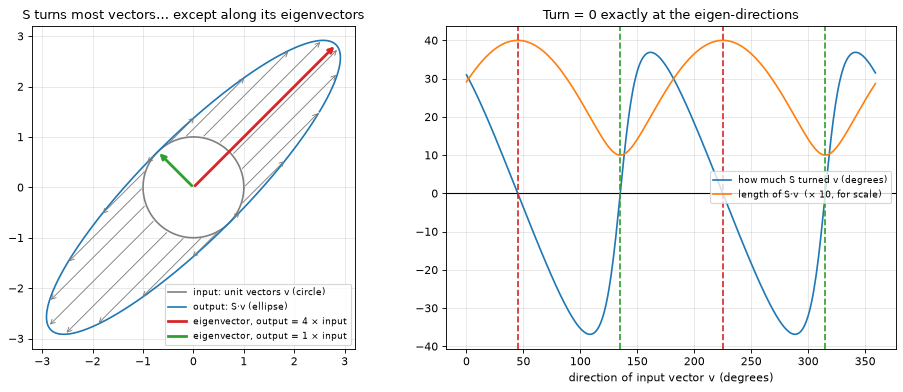

v at   0°: S·v = [2.5 1.5],  turned by  30.96°,  stretched to length 2.92
v at  45°: S·v = [2.828 2.828],  turned by   0.00°,  stretched to length 4.00
v at  90°: S·v = [1.5 2.5],  turned by -30.96°,  stretched to length 2.92
v at 135°: S·v = [-0.707  0.707],  turned by  -0.00°,  stretched to length 1.00


In [4]:
S = S_toy                                                # [[2.5, 1.5], [1.5, 2.5]]
angles = np.linspace(0, 2 * np.pi, 360, endpoint=False)
V = np.column_stack([np.cos(angles), np.sin(angles)])   # 360 unit vectors around a circle
SV = V @ S.T                                             # S applied to every one of them

turn = np.degrees(np.arctan2(SV[:, 1], SV[:, 0]) - angles)
turn = (turn + 180) % 360 - 180                          # wrap into [-180, 180)
stretch = np.linalg.norm(SV, axis=1)                     # how long S·v is (v had length 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ax = axes[0]
ax.plot(V[:, 0], V[:, 1], color="gray", label="input: unit vectors v (circle)")
ax.plot(SV[:, 0], SV[:, 1], color="tab:blue", label="output: S·v (ellipse)")
for i in range(0, 360, 20):
    draw_arrow(ax, V[i], SV[i] - V[i], "tab:gray", lw=0.8)
for lam, vec, color in zip(eigenvalues_toy, eigenvectors_toy.T, ["tab:red", "tab:green"]):
    draw_arrow(ax, (0, 0), lam * vec, color, f"eigenvector, output = {lam:.0f} × input")
ax.set_aspect("equal"); ax.legend(loc="lower right", fontsize=8)
ax.set_title("S turns most vectors… except along its eigenvectors")

ax = axes[1]
ax.plot(np.degrees(angles), turn, label="how much S turned v (degrees)")
ax.plot(np.degrees(angles), stretch * 10, label="length of S·v  (× 10, for scale)")
ax.axhline(0, color="black", lw=1)
for a in [45, 135, 225, 315]:
    ax.axvline(a, color="tab:red" if a in (45, 225) else "tab:green", ls="--")
ax.set_xlabel("direction of input vector v (degrees)"); ax.legend(fontsize=8)
ax.set_title("Turn = 0 exactly at the eigen-directions")
plt.tight_layout(); plt.show()

for deg in [0, 45, 90, 135]:
    v = np.array([np.cos(np.radians(deg)), np.sin(np.radians(deg))])
    print(f"v at {deg:3d}°: S·v = {S @ v},  turned by {turn[deg]:6.2f}°,  stretched to length {np.linalg.norm(S @ v):.2f}")

> **How to read this**
> * The grey circle (all directions) becomes the blue **ellipse**. The ellipse's long axis points at 45° and its
>   short axis at 135° — those are the eigenvectors.
> * Right plot: the blue “turn” curve crosses **zero** only at 45°, 135°, 225°, 315°. At 45° (red) the vector comes out
>   **4×** longer (λ = 4); at 135° (green) it comes out **1×** (λ = 1). At 0° or 90° it gets turned by ~31°.
> * The longest the output ever gets is 4 (at the red direction). That is the whole PCA story in one picture:
>   *the covariance matrix stretches data-space most along the direction in which the data is most spread out.*

<a id="lab-3"></a>

## Lab 3 · Try every direction: max variance = min error = top eigenvector

**Goal:** forget linear algebra for a moment and **brute-force** it. For 360 candidate directions we
project 300 points onto the line, then measure

* the **variance** of the projected points (how spread out the “shadows” are), and
* the **reconstruction error** (how far each point is from its shadow, squared, averaged).
  This is the familiar *line vs. point* approximation error, as in linear regression, with one difference:
  the distance is measured **perpendicular** to the line, not vertically.

**Note**:
- the 0.5 specified the granularity, i.e. 0.5º granularity based sampling, hence 360 points.
- the points from X2 are projected onto each of these lines.
- eigenvectors are calculated from the sample, not that the covariance matrix used for distribution is taken as is.

Claim: both are optimised by the same direction, and that direction is the top eigenvector.

* **Eigenvalues rank the directions.** The variance along each eigenvector equals its eigenvalue, so the eigenvector
  with the **largest** eigenvalue is the max-variance (min-error) direction and the one with the **smallest** is the
  min-variance (max-error) direction. Every other direction lands in between.

The proof is in the collapsed cell below; the code after it checks the claim by brute force.

<details>
<summary><b>Proof: why the top eigenvector gives the max variance <i>and</i> the min error (click to expand)</b></summary>

**Setup.** The points $x_1, \dots, x_n$ are centred (mean 0). $u$ is a unit vector ($u^\top u = 1$). Point $x_i$'s
shadow sits at position $z_i = u^\top x_i$ along the line, i.e. at the 2-D point $z_i u$.
$S = \frac{1}{n}\sum_i x_i x_i^\top$ is the covariance matrix, with eigenvectors $e_1, e_2$ (unit length, at right
angles) and eigenvalues $\lambda_1 \ge \lambda_2$.

**Step 1: the variance of the shadows is $u^\top S u$.**
The data is centred, so the $z_i$ have mean 0 and their variance is just the mean of their squares. A square is a
number times itself, $(u^\top x_i)^2 = (u^\top x_i)(x_i^\top u) = u^\top (x_i x_i^\top)\, u$, so

$$\text{Var}(z) = \frac{1}{n}\sum_i (u^\top x_i)^2 = u^\top \Big(\frac{1}{n}\sum_i x_i x_i^\top\Big) u = u^\top S\, u$$

**Step 2: $u^\top S u$ is largest at $u = e_1$, and the maximum is $\lambda_1$.**
Write $u$ in eigen-coordinates: $u = c_1 e_1 + c_2 e_2$. Since $e_1 \perp e_2$ and both have length 1,
$u^\top u = c_1^2 + c_2^2 = 1$. Then $S u = c_1 \lambda_1 e_1 + c_2 \lambda_2 e_2$, and

$$u^\top S u = \lambda_1 c_1^2 \underbrace{e_1^\top e_1}_{1} + \lambda_2 c_2^2 \underbrace{e_2^\top e_2}_{1} + c_1 c_2 (\lambda_1 + \lambda_2) \underbrace{e_1^\top e_2}_{0} = \lambda_1 c_1^2 + \lambda_2 c_2^2$$

The weights $c_1^2, c_2^2$ are $\ge 0$ and add up to 1, so $u^\top S u$ is a **weighted average of the eigenvalues**.
An average can never exceed its biggest ingredient, so the maximum is $\lambda_1$, reached with all the weight on
$e_1$ ($c_1 = \pm 1$, $c_2 = 0$, i.e. $u = \pm e_1$). In $p$ dimensions the same argument has $p$ terms.

*Calculus route (same answer):* maximise $u^\top S u - \lambda (u^\top u - 1)$. Setting the derivative
$2 S u - 2 \lambda u$ to zero gives $S u = \lambda u$, the eigenvector equation, and then
$u^\top S u = \lambda\, u^\top u = \lambda$. Every eigenvector is a candidate; the largest $\lambda$ wins.

**Step 3: the same $u$ gives the smallest error, and the minimum is $\lambda_2$.**
The shadow $z_i u$ lies along $u$, and the leftover $r_i = x_i - z_i u$ is at right angles to it:
$u^\top r_i = u^\top x_i - z_i\, u^\top u = z_i - z_i = 0$. Two perpendicular pieces, so Pythagoras applies:
$\lVert x_i \rVert^2 = z_i^2 + \lVert r_i \rVert^2$. Average over all points:

$$\underbrace{\frac{1}{n}\sum_i \lVert x_i \rVert^2}_{\text{total variance} \,=\, \mathrm{tr}(S) \,=\, \lambda_1 + \lambda_2} = \underbrace{u^\top S u}_{\text{variance kept}} + \underbrace{\frac{1}{n}\sum_i \lVert r_i \rVert^2}_{\text{reconstruction error}}$$

Here $\mathrm{tr}(S)$, the **trace** of $S$, is the sum of its diagonal entries: $S_{11} + S_{22}$ = Var(feature 1) +
Var(feature 2), i.e. the **total variance**. Why the left side equals it: writing $x_{i1}, x_{i2}$ for the two
coordinates of $x_i$, $\lVert x_i \rVert^2 = x_{i1}^2 + x_{i2}^2$, and averaging over $i$ gives $S_{11} + S_{22}$.
Why it also equals $\lambda_1 + \lambda_2$: measure the same points along the eigen-axes instead,
$\lVert x_i \rVert^2 = (e_1^\top x_i)^2 + (e_2^\top x_i)^2$ (Pythagoras again), and averaging gives
$e_1^\top S e_1 + e_2^\top S e_2 = \lambda_1 + \lambda_2$.

The left side does not depend on $u$, so $\text{error}(u) = \mathrm{tr}(S) - u^\top S u$: the $u$ that maximises the
variance is the $u$ that minimises the error. At $u = e_1$ the error is $(\lambda_1 + \lambda_2) - \lambda_1 = \lambda_2$.
Keeping $k$ of $p$ directions, the error is $\lambda_{k+1} + \dots + \lambda_p$.

*Where the error lives:* at $u = e_1$ every leftover $r_i$ is at right angles to $e_1$, and in 2-D the only such
direction is $e_2$. So $r_i = (e_2^\top x_i)\, e_2$ and the error is $\frac{1}{n}\sum_i (e_2^\top x_i)^2 = e_2^\top S e_2 = \lambda_2$,
the variance of the projections onto PC2.

**Check against the output below:** max variance 4.588 $= \lambda_1$, min error 0.427 $= \lambda_2$ (also the
variance of the projections onto PC2), and variance + error $= 5.015 = \mathrm{tr}(S)$ at every angle.

</details>

In [5]:
rng = np.random.default_rng(0)
X2 = rng.multivariate_normal(mean=[5, 3], cov=[[3.0, 2.0], [2.0, 2.0]], size=300)  # <- try changing cov
X2c = X2 - X2.mean(axis=0) # x  = x - µ (mean center)

thetas = np.arange(0, 180, 0.5)
variances, recon_errors = [], []
for theta in thetas:
    u = np.array([np.cos(np.radians(theta)), np.sin(np.radians(theta))])
    z = X2c @ u                              # shadow positions along the line
    shadows = np.outer(z, u)                 # shadows as 2-D points
    variances.append(z.var())
    recon_errors.append(np.mean(np.sum((X2c - shadows) ** 2, axis=1)))
variances, recon_errors = np.array(variances), np.array(recon_errors)

S2 = X2c.T @ X2c / len(X2c) # covariance matrix: sum of x xᵀ divided by n (no scaling by σ)
eigenvalues2, eigenvectors2 = np.linalg.eigh(S2)          # ascending
top_vector = eigenvectors2[:, -1]

print(f"brute force: best variance at θ = {thetas[variances.argmax()]:.1f}°, smallest error at θ = {thetas[recon_errors.argmin()]:.1f}°")
print(f"top eigenvector points at θ = {angle_of(top_vector):.1f}°")
print(f"max variance found = {variances.max():.3f}   largest eigenvalue  = {eigenvalues2[-1]:.3f}")
print(f"min error found    = {recon_errors.min():.3f}   smallest eigenvalue = {eigenvalues2[0]:.3f}")
second_vector = eigenvectors2[:, 0]                       # the other eigenvector (PC2)
print(f"variance of projections onto PC2 = {(X2c @ second_vector).var():.3f}   (= min error: what PC1 leaves out lies along PC2)")
print(f"variance + error is the same for every θ: min {np.min(variances + recon_errors):.3f}, max {np.max(variances + recon_errors):.3f}  (= total variance {np.trace(S2):.3f})")

brute force: best variance at θ = 37.5°, smallest error at θ = 37.5°
top eigenvector points at θ = 37.7°
max variance found = 4.588   largest eigenvalue  = 4.588
min error found    = 0.427   smallest eigenvalue = 0.427
variance of projections onto PC2 = 0.427   (= min error: what PC1 leaves out lies along PC2)
variance + error is the same for every θ: min 5.015, max 5.015  (= total variance 5.015)


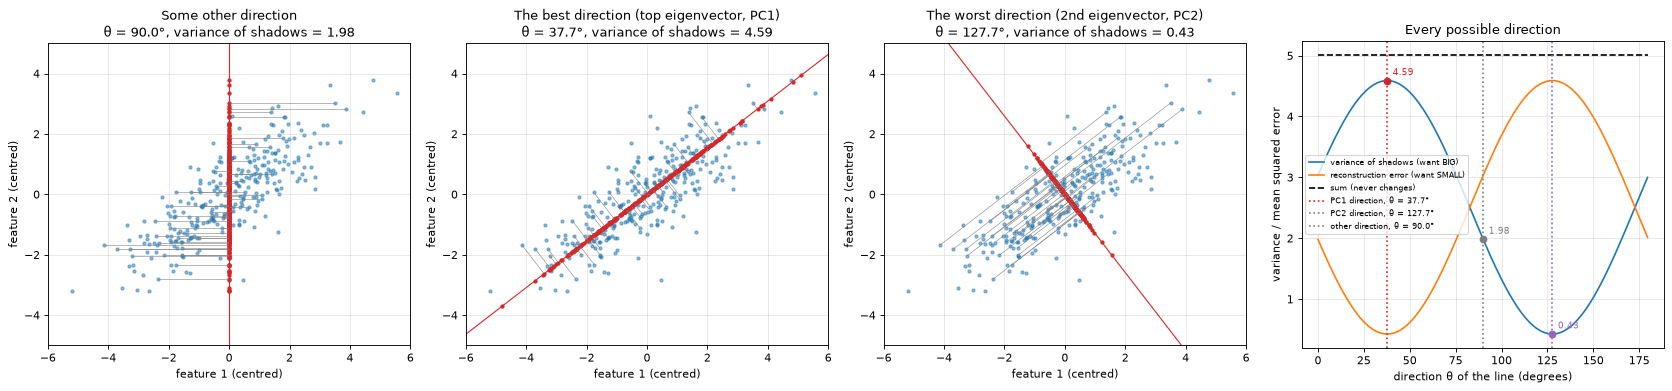

In [6]:
other_theta = 90                                           # <- try changing this
other_vector = np.array([np.cos(np.radians(other_theta)), np.sin(np.radians(other_theta))])

fig, axes = plt.subplots(1, 4, figsize=(21, 4.8))
for ax, u, title in [(axes[0], other_vector, "Some other direction"),
                     (axes[1], top_vector, "The best direction (top eigenvector, PC1)"),
                     (axes[2], second_vector, "The worst direction (2nd eigenvector, PC2)")]:
    shadows = np.outer(X2c @ u, u)
    ax.scatter(X2c[:, 0], X2c[:, 1], s=8, alpha=0.5)
    ax.scatter(shadows[:, 0], shadows[:, 1], s=8, color="tab:red")
    for p, s in zip(X2c[::6], shadows[::6]):
        ax.plot([p[0], s[0]], [p[1], s[1]], color="gray", lw=0.5)
    ax.axline((0, 0), u, color="tab:red", lw=1)
    ax.set_aspect("equal"); ax.set_xlim(-6, 6); ax.set_ylim(-5, 5)
    ax.set_xlabel("feature 1 (centred)"); ax.set_ylabel("feature 2 (centred)")
    ax.set_title(f"{title}\nθ = {angle_of(u):.1f}°, variance of shadows = {(X2c @ u).var():.2f}")

ax = axes[3]
ax.plot(thetas, variances, label="variance of shadows (want BIG)")
ax.plot(thetas, recon_errors, label="reconstruction error (want SMALL)")
ax.plot(thetas, variances + recon_errors, "k--", label="sum (never changes)")
for u, lam, color, name in [(top_vector, eigenvalues2[-1], "tab:red", "PC1"),
                            (second_vector, eigenvalues2[0], "tab:purple", "PC2"),
                            (other_vector, (X2c @ other_vector).var(), "tab:gray", "other")]:
    ax.axvline(angle_of(u), color=color, ls=":", label=f"{name} direction, θ = {angle_of(u):.1f}°")
    ax.plot(angle_of(u), lam, "o", color=color)           # variance of shadows at this angle (= eigenvalue for PC1/PC2)
    ax.annotate(f"{lam:.2f}", (angle_of(u), lam), textcoords="offset points", xytext=(5, 5), color=color, fontsize=8)
ax.set_xlabel("direction θ of the line (degrees)"); ax.set_ylabel("variance / mean squared error")
ax.legend(fontsize=7)
ax.set_title("Every possible direction")
plt.tight_layout(); plt.show()

> **How to read this**
> * First three panels: red dots are the **shadows** (projections). On the PC1 line they are spread out and the grey
>   “error” segments are short. On the PC2 line they are bunched up and the segments are long: PC2 is the **worst**
>   possible line, with the smallest shadow variance (λ₂). Any other line, like 90° in the first panel, lands in
>   between. Change `other_theta` to try more.
> * Right: the variance curve peaks **at the same angle** where the error curve bottoms out, and that angle is the
>   one the top eigenvector gave us (red dotted line). Brute force and linear algebra agree. At the PC2 angle, 90°
>   away (purple dotted line), it is the other way round: variance bottoms out at λ₂ and error peaks at λ₁.
> * The dashed line is flat: *variance kept + variance lost = total variance*, always (Pythagoras). So
>   “keep the most spread” and “lose the least information” are literally the same goal.
> * The max variance equals the **largest eigenvalue**, the min error equals the **smallest eigenvalue**.
> * Where does that error live? In 2-D, whatever a point loses when projected onto PC1 lies entirely along the
>   **second eigenvector** (PC2). So the min error is simply the variance of the projections onto PC2 = λ₂.

<a id="lab-4"></a>

## Lab 4 · Three ways to compute PCA give the same answer

**Goal:** show that (1) eigen-decomposition of the covariance matrix, (2) SVD of the centred data, and
(3) `sklearn.decomposition.PCA` are the same thing. Then show that the new features are **uncorrelated**.

> scikit-learn divides by `n − 1` (the “sample” covariance) instead of `n`. That rescales every eigenvalue by the
> same factor and **does not change the directions** or the explained-variance *ratios*.

<details>
<summary><b>What is SVD? (click to expand)</b></summary>

**In one line.** The **singular value decomposition** writes *any* table of numbers $X$ ($n$ rows × $p$ columns) as a
product of three simpler pieces:

$$X = U\,\Sigma\,V^\top$$

**The three pieces**, with shapes for this lab's centred data `X2c` ($n = 300$ points, $p = 2$ features, `full_matrices=False`):

| Piece | Shape | What it is | In the code |
|---|---|---|---|
| $V$ | $p \times p$ (2 × 2) | $p$ unit directions at right angles in feature space: **the PC directions** | `Vt` (one direction per **row**) |
| $\Sigma$ | $p \times p$, diagonal | the **singular values** $\sigma_1 \ge \sigma_2 \ge 0$: how much the data stretches along each direction | `sing` (just the diagonal) |
| $U$ | $n \times p$ (300 × 2) | each point's coordinate along each direction, rescaled so every column has length 1 | `U` |

Read row by row, it says each point is a mix of the directions: $x_i = \sum_j U_{ij}\,\sigma_j\, v_j$. Keeping only the
first $k$ terms gives the best $k$-dimensional approximation of the data, which is exactly PCA's reconstruction (Lab 7).

**Why it gives PCA.** Put the SVD into $X^\top X$. Because the columns of $U$ are unit length and at right angles,
$U^\top U = I$, so

$$X^\top X = (U \Sigma V^\top)^\top (U \Sigma V^\top) = V \Sigma\, \underbrace{U^\top U}_{I}\, \Sigma V^\top = V \Sigma^2 V^\top$$

Multiply both sides on the right by $V$ (and use $V^\top V = I$): $X^\top X\, V = V \Sigma^2$. Column by column that is
$X^\top X\, v_j = \sigma_j^2\, v_j$, and dividing by $n - 1$:

$$S\, v_j = \frac{\sigma_j^2}{n - 1}\, v_j$$

So, without ever building $S$:

* the $v_j$ are the **eigenvectors of $S$**, i.e. the PC directions (rows of `Vt` = `pca.components_`);
* the **eigenvalues** are $\lambda_j = \sigma_j^2 / (n - 1)$, which is the line `svd_eigvals = sing ** 2 / (n - 1)`;
* the **scores** are $X V = U \Sigma$ (`U * sing`), the same numbers `pca.transform` returns.

**Why software prefers it.** Forming $X^\top X$ squares every number, so tiny values can get lost to rounding. SVD works
on $X$ directly, which is more accurate, and truncated/randomised SVD can find just the top $k$ directions without
ever building the $p \times p$ matrix (handy when $p$ is huge). scikit-learn's `PCA` uses SVD internally.

**Signs.** As with eigenvectors, each $v_j$ may come out flipped (together with the matching column of $U$). That is
why the code compares **absolute** dot products.

</details>

In [7]:
n = len(X2)

# (1) eigen-decomposition of the covariance matrix
S_sample = X2c.T @ X2c / (n - 1)
eigvals, eigvecs = np.linalg.eigh(S_sample)
eigvals, eigvecs = eigvals[::-1], eigvecs[:, ::-1]           # largest first

# (2) singular value decomposition of the centred data:  X2c = U · diag(sing) · Vt
U, sing, Vt = np.linalg.svd(X2c, full_matrices=False)
svd_eigvals = sing ** 2 / (n - 1)

# (3) scikit-learn
pca2 = PCA().fit(X2)

print("eigenvalues  via eig :", eigvals)
print("eigenvalues  via SVD :", svd_eigvals)
print("eigenvalues  sklearn :", pca2.explained_variance_)
for i in range(2):
    # show that dot product = 1 meaning the eigenvectors from different methods are completely identical.
    print(f"PC{i+1}: |eig·svd| = {abs(eigvecs[:, i] @ Vt[i]):.6f}   |eig·sklearn| = {abs(eigvecs[:, i] @ pca2.components_[i]):.6f}   (1.0 = same axis)")

scores2 = pca2.transform(X2)
print("\ncorrelation matrix of ORIGINAL features:\n", np.corrcoef(X2.T))
print("correlation matrix of PC scores:\n", np.corrcoef(scores2.T))

eigenvalues  via eig : [4.604 0.428]
eigenvalues  via SVD : [4.604 0.428]
eigenvalues  sklearn : [4.604 0.428]
PC1: |eig·svd| = 1.000000   |eig·sklearn| = 1.000000   (1.0 = same axis)
PC2: |eig·svd| = 1.000000   |eig·sklearn| = 1.000000   (1.0 = same axis)

correlation matrix of ORIGINAL features:
 [[1.    0.821]
 [0.821 1.   ]]
correlation matrix of PC scores:
 [[1. 0.]
 [0. 1.]]


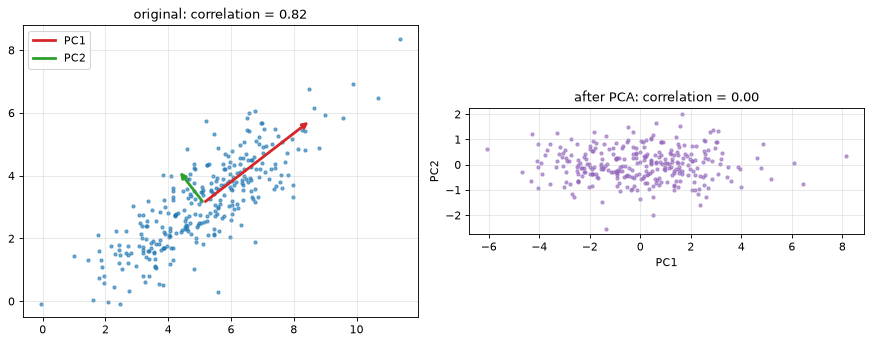

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(X2[:, 0], X2[:, 1], s=8, alpha=0.6)
for vec, lam, color, name in zip(pca2.components_, pca2.explained_variance_, ["tab:red", "tab:green"], ["PC1", "PC2"]):
    draw_arrow(axes[0], pca2.mean_, 2 * np.sqrt(lam) * vec, color, name)
axes[0].set_aspect("equal"); axes[0].legend(); axes[0].set_title(f"original: correlation = {np.corrcoef(X2.T)[0, 1]:.2f}")
axes[1].scatter(scores2[:, 0], scores2[:, 1], s=8, alpha=0.6, color="tab:purple")
axes[1].set_aspect("equal"); axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
axes[1].set_title(f"after PCA: correlation = {np.corrcoef(scores2.T)[0, 1]:.2f}")
plt.tight_layout(); plt.show()

> **How to read this**
> * All three methods print the same eigenvalues, and the dot-products are `1.000000`: same axes.
>   This is why the README says “computers actually use SVD” — it is the same answer, computed more stably.
> * The original features are strongly correlated (≈ 0.8). The PC scores have correlation **0.00**. PCA turns
>   correlated features into **uncorrelated** ones — the cloud on the right is “axis-aligned”.

---

<a id="part-b"></a>

# Part B — Why PCA is useful in machine learning

From here on we use the **digits** dataset that ships with scikit-learn: 1,797 handwritten digits, each an
8 × 8 grey-scale image, i.e. **64 features** (one per pixel, values 0–16). 64 dimensions is impossible to look at —
a perfect place for PCA.

All pixels are measured in the same unit (ink intensity 0–16), so we **do not standardise** here.
Lab 10 shows what happens when features have *different* units.

<a id="lab-5"></a>

## Lab 5 · How many components do we need? (explained variance)

data shape: (1797, 64) -> 1797 samples x 64 features


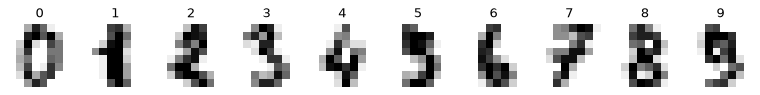

In [9]:
digits = load_digits()
X_digits, y_digits = digits.data, digits.target
print("data shape:", X_digits.shape, "-> 1797 samples x 64 features")

fig, axes = plt.subplots(1, 10, figsize=(12, 1.6))
for ax, image, label in zip(axes, X_digits, y_digits):
    ax.imshow(image.reshape(8, 8), cmap="gray_r"); ax.set_title(label); ax.axis("off")
plt.show()

first 5 explained-variance ratios: [0.149 0.136 0.118 0.084 0.058]
components needed for 90% variance: 21   95%: 29   99%: 41   (out of 64)
sklearn shortcut  PCA(n_components=0.95) picked: 29


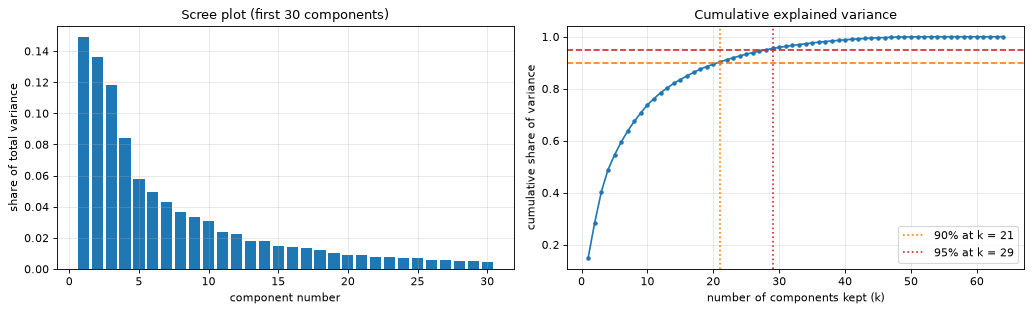

In [10]:
pca_digits = PCA().fit(X_digits)                       # keep all 64 components for now
ratio = pca_digits.explained_variance_ratio_
cumulative = np.cumsum(ratio)
k90 = np.searchsorted(cumulative, 0.90) + 1
k95 = np.searchsorted(cumulative, 0.95) + 1
k99 = np.searchsorted(cumulative, 0.99) + 1

print("first 5 explained-variance ratios:", ratio[:5])
print(f"components needed for 90% variance: {k90}   95%: {k95}   99%: {k99}   (out of 64)")
print("sklearn shortcut  PCA(n_components=0.95) picked:", PCA(n_components=0.95).fit(X_digits).n_components_)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(range(1, 31), ratio[:30])
axes[0].set_xlabel("component number"); axes[0].set_ylabel("share of total variance")
axes[0].set_title("Scree plot (first 30 components)")
axes[1].plot(range(1, 65), cumulative, marker=".")
for level, k, color in [(0.90, k90, "tab:orange"), (0.95, k95, "tab:red")]:
    axes[1].axhline(level, color=color, ls="--"); axes[1].axvline(k, color=color, ls=":", label=f"{level:.0%} at k = {k}")
axes[1].set_xlabel("number of components kept (k)"); axes[1].set_ylabel("cumulative share of variance")
axes[1].set_title("Cumulative explained variance"); axes[1].legend()
plt.tight_layout(); plt.show()

> **How to read this**
> * **Scree plot** (left): each bar is one component's share of the total spread. The bars drop fast, then flatten
>   into a long tail of tiny components — that tail is mostly pixel-level noise.
> * **Cumulative plot** (right): read off how many components you need for a target. Here ~21 components keep 90 %
>   and ~29 keep 95 % of the variance — **less than half of the 64 pixels**.
> * `PCA(n_components=0.95)` does that look-up for you. (`explained_variance_ratio_` is something PCA *reports*
>   after fitting; you cannot set it.)
> * Note: some pixels on the border are always blank (variance 0), so the last few components explain exactly 0.

<a id="lab-6"></a>

## Lab 6 · What do the components look like?

**Goal:** a principal component is a direction in 64-D pixel space, so we can *draw it as an 8 × 8 image*.
Then use the first 2 components as a 2-D map of all 1,797 digits.

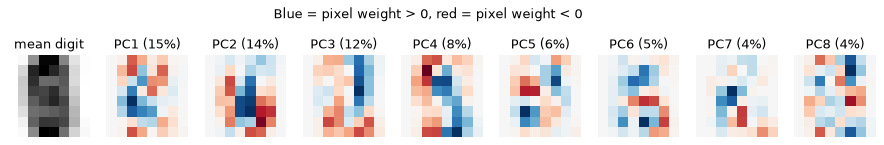

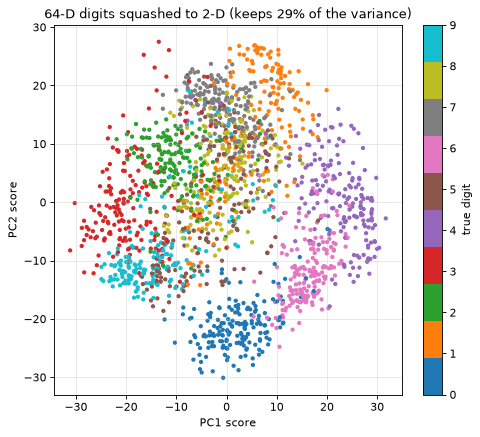

In [11]:
fig, axes = plt.subplots(1, 9, figsize=(14, 2))
axes[0].imshow(pca_digits.mean_.reshape(8, 8), cmap="gray_r"); axes[0].set_title("mean digit"); axes[0].axis("off")
for i, ax in enumerate(axes[1:]):
    component = pca_digits.components_[i].reshape(8, 8)
    limit = np.abs(component).max()
    ax.imshow(component, cmap="RdBu", vmin=-limit, vmax=limit)
    ax.set_title(f"PC{i+1} ({ratio[i]:.0%})"); ax.axis("off")
plt.suptitle("Blue = pixel weight > 0, red = pixel weight < 0", y=1.05)
plt.show()

scores_digits = pca_digits.transform(X_digits)
plt.figure(figsize=(7, 6))
points = plt.scatter(scores_digits[:, 0], scores_digits[:, 1], c=y_digits, cmap="tab10", s=8)
plt.colorbar(points, ticks=range(10), label="true digit")
plt.xlabel("PC1 score"); plt.ylabel("PC2 score")
plt.title(f"64-D digits squashed to 2-D (keeps {cumulative[1]:.0%} of the variance)")
plt.show()

> **How to read this**
> * Each component is a **pattern of pixel weights**. A digit's PC1 score is “how much this digit looks like the
>   blue parts of PC1 minus the red parts”. Every component uses *all* 64 pixels — PCA builds new features, it
>   does not pick old ones.
> * The 2-D map is built **without ever looking at the labels**, yet 0s, 4s, 6s and 3s already form their own
>   islands. Some digits (1, 7, 9, 8) overlap — 2 dimensions with ~29 % of the variance are not enough for them.

<a id="lab-7"></a>

## Lab 7 · Compression: rebuild digits from a few numbers

**Goal:** store each digit as only *k* PC scores, then rebuild it with `inverse_transform`.
Check the README claim that **reconstruction error = sum of the eigenvalues we threw away.**

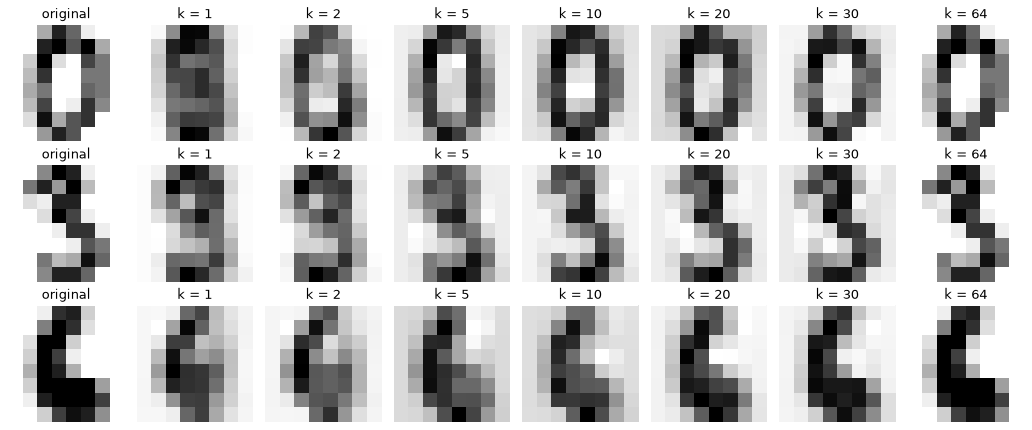

largest |error - sum of dropped eigenvalues| over all k: 2.2737367544323206e-13


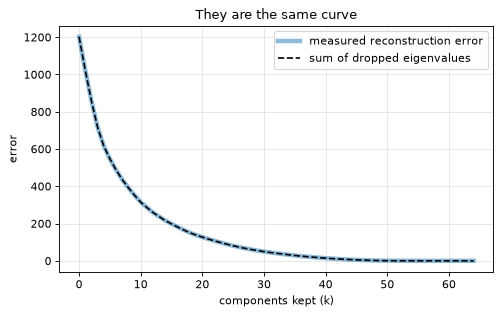

k = 10: store  18674 numbers instead of 115008 (16%)
k = 20: store  37284 numbers instead of 115008 (32%)
k = 30: store  55894 numbers instead of 115008 (49%)


In [12]:
def reconstruct(fitted_pca, X, k):
    """Project X onto the first k components of fitted_pca and map back to the original feature space."""
    top = fitted_pca.components_[:k]
    return (X - fitted_pca.mean_) @ top.T @ top + fitted_pca.mean_


ks = [1, 2, 5, 10, 20, 30, 64]
examples = [0, 3, 26]
fig, axes = plt.subplots(len(examples), len(ks) + 1, figsize=(13, 5.5))
for row, idx in enumerate(examples):
    axes[row, 0].imshow(X_digits[idx].reshape(8, 8), cmap="gray_r"); axes[row, 0].set_title("original")
    for col, k in enumerate(ks, start=1):
        axes[row, col].imshow(reconstruct(pca_digits, X_digits[[idx]], k).reshape(8, 8), cmap="gray_r")
        axes[row, col].set_title(f"k = {k}")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout(); plt.show()

n_digits = len(X_digits)
errors = [np.sum((X_digits - reconstruct(pca_digits, X_digits, k)) ** 2) / (n_digits - 1) for k in range(65)]
dropped = [pca_digits.explained_variance_[k:].sum() for k in range(65)]
print("largest |error - sum of dropped eigenvalues| over all k:", np.max(np.abs(np.array(errors) - np.array(dropped))))

plt.figure(figsize=(7, 4))
plt.plot(range(65), errors, lw=4, alpha=0.5, label="measured reconstruction error")
plt.plot(range(65), dropped, "k--", label="sum of dropped eigenvalues")
plt.xlabel("components kept (k)"); plt.ylabel("error"); plt.legend(); plt.title("They are the same curve")
plt.show()

for k in [10, 20, 30]:
    stored = n_digits * k + k * 64 + 64          # scores + components + mean
    print(f"k = {k:2d}: store {stored:6d} numbers instead of {n_digits * 64} ({stored / (n_digits * 64):.0%})")

> **How to read this**
> * With k = 1 or 2 every digit looks like a blurry blob; by k ≈ 10 they are readable; by k ≈ 20–30 they are
>   nearly identical to the original. k = 64 is a perfect copy (nothing dropped).
> * The two curves overlap perfectly (the printed difference is ~1e-12, i.e. rounding). The information PCA
>   throws away is *exactly* the variance of the components it drops — so the eigenvalues tell you the price of
>   compression **before** you compress.

<a id="lab-8"></a>

## Lab 8 · Denoising: small components are mostly noise

**Goal:** add random noise to every pixel, fit PCA on the noisy training images, keep only *k* components,
and rebuild the noisy *test* images. Real structure lives in the big components; random noise is spread thinly
over *all* directions, so dropping the small components drops mostly noise.

error of noisy images vs clean: 15.94
best k = 15, error after PCA denoising: 7.27


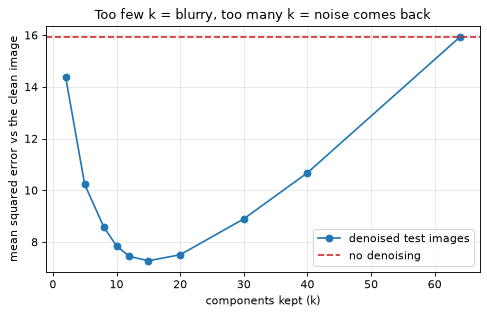

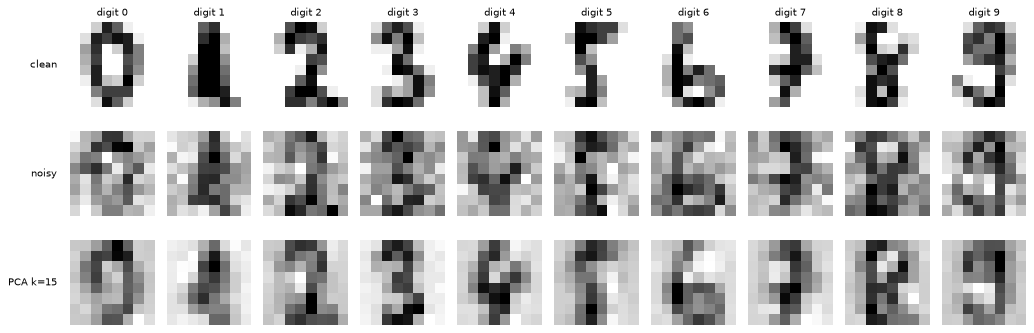

In [13]:
rng = np.random.default_rng(0)
noise_level = 4.0                                                     # <- try changing this
X_noisy = X_digits + rng.normal(0, noise_level, X_digits.shape)
X_tr_noisy, X_te_noisy, X_tr_clean, X_te_clean, y_tr, y_te = train_test_split(
    X_noisy, X_digits, y_digits, test_size=0.25, random_state=0)                # labels only used to pick images to show

k_values = [2, 5, 8, 10, 12, 15, 20, 30, 40, 64]
mse = []
for k in k_values:
    pca_k = PCA(n_components=k).fit(X_tr_noisy)                       # fit on noisy TRAINING data only
    X_te_denoised = pca_k.inverse_transform(pca_k.transform(X_te_noisy))
    mse.append(np.mean((X_te_denoised - X_te_clean) ** 2))
best_k = k_values[int(np.argmin(mse))]
print(f"error of noisy images vs clean: {np.mean((X_te_noisy - X_te_clean) ** 2):.2f}")
print(f"best k = {best_k}, error after PCA denoising: {min(mse):.2f}")

plt.figure(figsize=(7, 4))
plt.plot(k_values, mse, marker="o", label="denoised test images")
plt.axhline(np.mean((X_te_noisy - X_te_clean) ** 2), color="tab:red", ls="--", label="no denoising")
plt.xlabel("components kept (k)"); plt.ylabel("mean squared error vs the clean image"); plt.legend()
plt.title("Too few k = blurry, too many k = noise comes back"); plt.show()

pca_best = PCA(n_components=best_k).fit(X_tr_noisy)
show = [np.flatnonzero(y_te == digit)[0] for digit in range(10)]       # first test image of each digit 0-9
denoised = pca_best.inverse_transform(pca_best.transform(X_te_noisy[show]))
fig, axes = plt.subplots(3, 10, figsize=(13, 4.5))
for col, idx in enumerate(show):
    for row, image in enumerate([X_te_clean[idx], X_te_noisy[idx], denoised[col]]):
        axes[row, col].imshow(image.reshape(8, 8), cmap="gray_r"); axes[row, col].axis("off")
    axes[0, col].set_title(f"digit {y_te[idx]}", fontsize=9)
for row, name in enumerate(["clean", "noisy", f"PCA k={best_k}"]):
    axes[row, 0].annotate(name, xy=(-0.15, 0.5), xycoords="axes fraction", ha="right", va="center", fontsize=9)
plt.tight_layout(); plt.show()

> **How to read this**
> * The error curve is **U-shaped**: with very few components the rebuilt digits are too blurry; with all 64 we
>   rebuild the noise too and are back at the red “no denoising” line. In between there is a sweet spot.
> * The image grid shows the first test image of each digit 0–9 (clean, noisy, denoised). The bottom row is
>   clearly cleaner than the middle row. PCA never saw a clean image — it
>   simply kept the directions where the *shared* structure of digits lives.

<a id="lab-9"></a>

## Lab 9 · PCA inside a classifier: smaller model, same accuracy

**Goal:** train a logistic-regression digit classifier on the first *k* PC scores and see how accuracy changes with *k*.

Important habit: PCA goes **inside a `Pipeline`**, so it is fitted on the **training split only**. Fitting PCA on all
data before splitting lets information from the test set leak into training.

k =  1 components -> test accuracy 0.367
k =  2 components -> test accuracy 0.581
k =  3 components -> test accuracy 0.691
k =  5 components -> test accuracy 0.844
k =  8 components -> test accuracy 0.906
k = 10 components -> test accuracy 0.937
k = 15 components -> test accuracy 0.957
k = 20 components -> test accuracy 0.956
k = 30 components -> test accuracy 0.967
k = 40 components -> test accuracy 0.970
k = 64 components -> test accuracy 0.970
no PCA (all 64 pixels) -> test accuracy 0.970


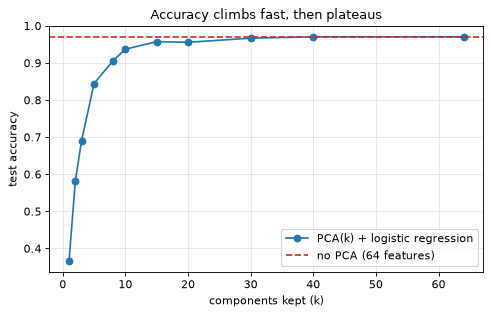

In [14]:
X_tr, X_te, y_tr, y_te = train_test_split(X_digits / 16.0, y_digits, test_size=0.3, stratify=y_digits, random_state=0)

k_values = [1, 2, 3, 5, 8, 10, 15, 20, 30, 40, 64]
accuracies = []
for k in k_values:
    model = make_pipeline(PCA(n_components=k), LogisticRegression(max_iter=5000))
    model.fit(X_tr, y_tr)
    accuracies.append(model.score(X_te, y_te))
baseline = LogisticRegression(max_iter=5000).fit(X_tr, y_tr).score(X_te, y_te)

for k, acc in zip(k_values, accuracies):
    print(f"k = {k:2d} components -> test accuracy {acc:.3f}")
print(f"no PCA (all 64 pixels) -> test accuracy {baseline:.3f}")

plt.figure(figsize=(7, 4))
plt.plot(k_values, accuracies, marker="o", label="PCA(k) + logistic regression")
plt.axhline(baseline, color="tab:red", ls="--", label="no PCA (64 features)")
plt.xlabel("components kept (k)"); plt.ylabel("test accuracy"); plt.legend()
plt.title("Accuracy climbs fast, then plateaus"); plt.show()

> **How to read this**
> * Accuracy shoots up over the first ~10 components and then **plateaus** near the no-PCA baseline
>   (the “increase till a limit” effect from the original notes).
> * So a model on ~20–30 numbers per image is about as good as one on 64 — fewer weights, faster training, less
>   memory. On wide data (thousands of features) this saving is what makes PCA worth it.
> * PCA did not *create* information: it can at best tie the baseline. Its value here is “same accuracy, smaller
>   input”, plus the noise removal from Lab 8.

---

<a id="part-c"></a>

# Part C — Where PCA fails, and *why*

Every lab below breaks one of PCA's hidden assumptions:

| Lab | Hidden assumption | What breaks |
|---|---|---|
| 10 | All features are on comparable scales | the feature with the biggest *unit* wins |
| 11 | The structure is **linear** (flat) | curved structure gets folded on top of itself |
| 12 | Big variance = important | the label lives in a small-variance direction |
| 13 | No extreme points | a handful of outliers steal PC1 |
| 14 | Features are correlated | nothing to compress |
| 15 | Uncorrelated = separated | mixed signals stay mixed |

<a id="lab-10"></a>

## Lab 10 · Features with different units (wine dataset)

The wine dataset has 13 chemical measurements. One of them, **proline**, is measured in numbers around
300–1700; others (like hue) are around 0.5–1.7. Variance is measured in *squared units*, so proline's variance is
tens of thousands of times bigger — not because it matters more, but because of its unit.

In [15]:
wine = load_wine()
X_wine, y_wine, names = wine.data, wine.target, np.array(wine.feature_names)
stds = X_wine.std(axis=0)
for i in np.argsort(stds)[::-1][:4]:
    print(f"{names[i]:30s} std = {stds[i]:8.2f}")
print("...")
for i in np.argsort(stds)[:2]:
    print(f"{names[i]:30s} std = {stds[i]:8.2f}")

pca_raw = PCA(n_components=2).fit(X_wine)
scaled_pca = make_pipeline(StandardScaler(), PCA(n_components=2)).fit(X_wine)
pca_scaled = scaled_pca[-1]

print("\nWITHOUT scaling: explained variance ratio", pca_raw.explained_variance_ratio_)
print("  biggest weights in PC1:", ", ".join(f"{names[i]} {pca_raw.components_[0, i]:+.3f}" for i in np.argsort(-np.abs(pca_raw.components_[0]))[:3]))
print("WITH scaling:    explained variance ratio", pca_scaled.explained_variance_ratio_)

proline                        std =   314.02
magnesium                      std =    14.24
alcalinity_of_ash              std =     3.33
color_intensity                std =     2.31
...
nonflavanoid_phenols           std =     0.12
hue                            std =     0.23

WITHOUT scaling: explained variance ratio [0.998 0.002]
  biggest weights in PC1: proline +1.000, magnesium +0.018, alcalinity_of_ash -0.005
WITH scaling:    explained variance ratio [0.362 0.192]


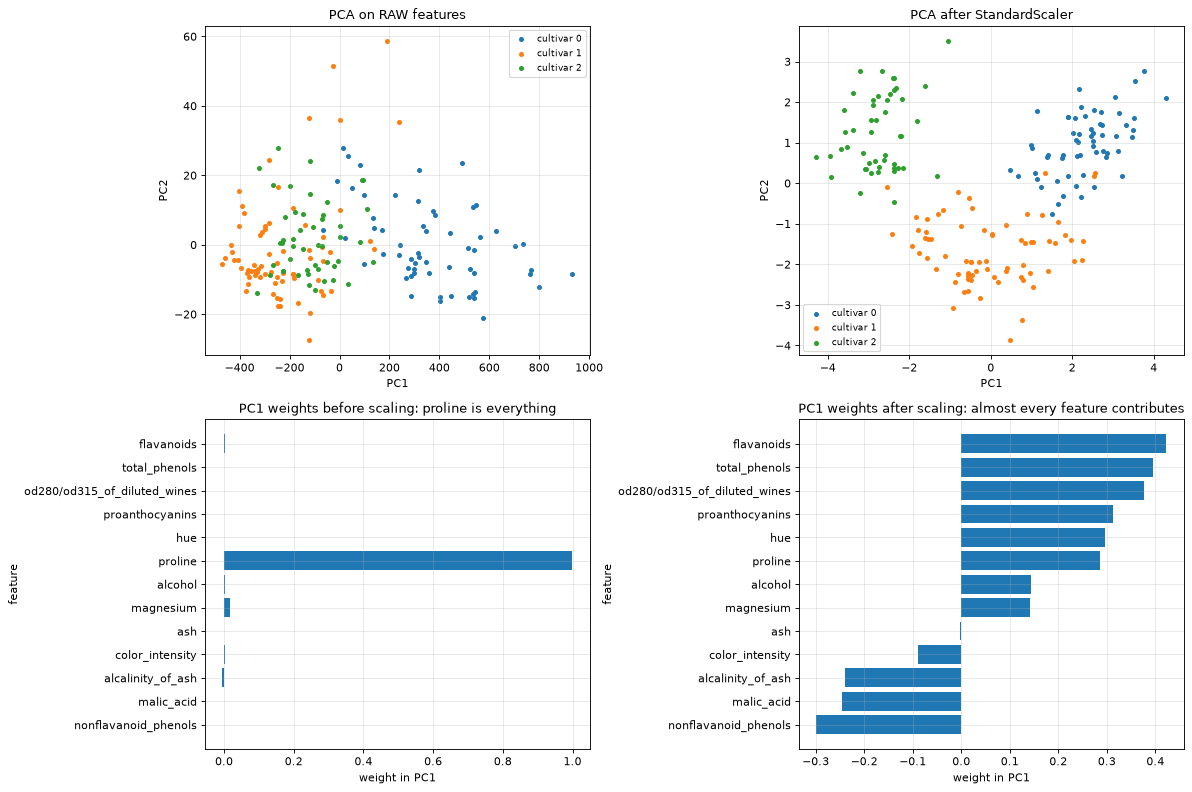

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, Z, title in [(axes[0, 0], pca_raw.transform(X_wine), "PCA on RAW features"),
                     (axes[0, 1], scaled_pca.transform(X_wine), "PCA after StandardScaler")]:
    for c, color in zip(range(3), ["tab:blue", "tab:orange", "tab:green"]):
        ax.scatter(Z[y_wine == c, 0], Z[y_wine == c, 1], s=12, color=color, label=f"cultivar {c}")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title(title); ax.legend(fontsize=8)

order = np.argsort(pca_scaled.components_[0])          # same feature order in both bar charts, for comparison
for ax, weights, title in [(axes[1, 0], pca_raw.components_[0], "PC1 weights before scaling: proline is everything"),
                           (axes[1, 1], pca_scaled.components_[0], "PC1 weights after scaling: almost every feature contributes")]:
    ax.barh(names[order], weights[order])
    ax.set_xlabel("weight in PC1"); ax.set_ylabel("feature"); ax.set_title(title)
plt.tight_layout(); plt.show()

> **How to read this**
> * **Without scaling** PC1 “explains” ~99.8 % of the variance — and it is almost 100 % proline. PCA just
>   rediscovered *“the column with the biggest numbers”*: in the bottom-left bars proline's weight is 1.00 and
>   every other weight is ≈ 0. The three wine types overlap heavily (top left).
> * **With scaling** (each feature → mean 0, std 1) the variance is shared across components and the three
>   cultivars separate into clean groups (top right).
> * **Interpretability** (bottom right): even after scaling, PC1 is a weighted mix of almost all 13 chemicals (only ash
>   is ≈ 0). If someone asks “what is PC1, physically?”, there is no single-word answer. When features must stay
>   explainable (e.g. credit or medical decisions), PCA makes that harder.
> * **Rule:** different units → standardise first. Same units (pixels) → usually leave as is.

<a id="lab-11"></a>

## Lab 11 · Curved (non-linear) structure: two circles

PCA can only **rotate and drop flat directions**. If the pattern is curved, no straight line captures it.
Kernel PCA first maps the data into a richer space (implicitly) where the curve becomes flat, then does PCA there.

classifier on 1 PCA component        : accuracy 0.46  (coin flip = 0.50)
classifier on 1 kernel-PCA component : accuracy 1.00


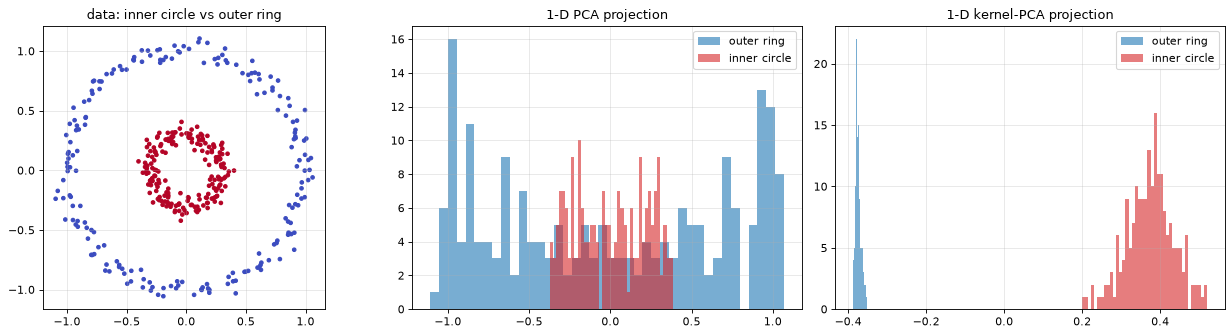

In [17]:
X_circ, y_circ = make_circles(n_samples=400, factor=0.3, noise=0.05, random_state=0)

z_pca = PCA(n_components=1).fit_transform(X_circ)[:, 0]
z_kpca = KernelPCA(n_components=1, kernel="rbf", gamma=5).fit_transform(X_circ)[:, 0]   # <- try gamma = 1 or 10

acc_pca = cross_val_score(make_pipeline(PCA(n_components=1), LogisticRegression()), X_circ, y_circ, cv=5).mean()
acc_kpca = cross_val_score(make_pipeline(KernelPCA(n_components=1, kernel="rbf", gamma=5), LogisticRegression()),
                           X_circ, y_circ, cv=5).mean()
print(f"classifier on 1 PCA component        : accuracy {acc_pca:.2f}  (coin flip = 0.50)")
print(f"classifier on 1 kernel-PCA component : accuracy {acc_kpca:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
axes[0].scatter(X_circ[:, 0], X_circ[:, 1], c=y_circ, cmap="coolwarm", s=10)
axes[0].set_aspect("equal"); axes[0].set_title("data: inner circle vs outer ring")
for ax, z, title in [(axes[1], z_pca, "1-D PCA projection"), (axes[2], z_kpca, "1-D kernel-PCA projection")]:
    ax.hist(z[y_circ == 0], bins=40, alpha=0.6, color="tab:blue", label="outer ring")
    ax.hist(z[y_circ == 1], bins=40, alpha=0.6, color="tab:red", label="inner circle")
    ax.set_title(title); ax.legend()
plt.tight_layout(); plt.show()

> **How to read this**
> * Linear PCA “looks at the rings from the side”: the inner circle lands in the middle of the outer ring's shadow,
>   so the two histograms sit on top of each other and a classifier is near a coin flip.
> * Kernel PCA's single component puts the inner circle on one side and the outer ring on the other — the
>   histograms do not overlap and the classifier is perfect.
> * Kernel PCA has a knob (`gamma`, how “local” the similarity is). Try `gamma = 1` (too smooth: fails like PCA)
>   and `gamma = 10` (too local: partly fails). Linear PCA has no such knob — and no way to succeed here.
> * Same failure, other shapes: Swiss rolls, spirals, images under rotation. Alternatives: Kernel PCA,
>   Isomap / UMAP / t-SNE (for visualisation), autoencoders.

<a id="lab-12"></a>

## Lab 12 · High variance ≠ useful for the label

PCA never looks at the labels `y`. It keeps the directions with the most spread. If the classes differ along a
direction that has **little** spread, PCA throws exactly that direction away. \
LDA (Linear Discriminant Analysis) uses the labels and looks for the direction that **separates the classes**.

PC1 explains 96% of the variance
accuracy using only PC1 (what PCA keeps)    : 0.55
accuracy using only PC2 (what PCA throws out): 0.99
accuracy using the 1 LDA direction          : 0.98


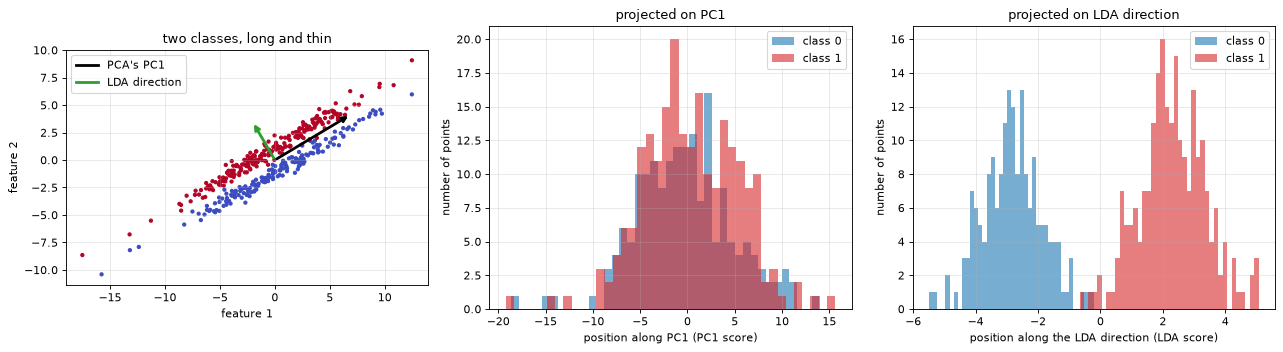

In [18]:
rng = np.random.default_rng(0)
n_points = 400
y12 = rng.integers(0, 2, n_points)
along = rng.normal(0, 5, n_points)                                      # big spread, same for both classes
across = np.where(y12 == 1, 1.0, -1.0) + rng.normal(0, 0.4, n_points)   # small spread, but it IS the label
tilt = np.radians(30)
rotation = np.array([[np.cos(tilt), -np.sin(tilt)], [np.sin(tilt), np.cos(tilt)]])
X12 = np.column_stack([along, across]) @ rotation.T

X12_tr, X12_te, y12_tr, y12_te = train_test_split(X12, y12, test_size=0.3, random_state=0)
pca12 = PCA(n_components=2).fit(X12_tr)
lda12 = LinearDiscriminantAnalysis(n_components=1).fit(X12_tr, y12_tr)


def accuracy_on(feature_tr, feature_te):
    """Test accuracy of a logistic regression trained on a single feature column."""
    clf = LogisticRegression().fit(feature_tr.reshape(-1, 1), y12_tr)
    return clf.score(feature_te.reshape(-1, 1), y12_te)


Z_tr, Z_te = pca12.transform(X12_tr), pca12.transform(X12_te)
print(f"PC1 explains {pca12.explained_variance_ratio_[0]:.0%} of the variance")
print(f"accuracy using only PC1 (what PCA keeps)    : {accuracy_on(Z_tr[:, 0], Z_te[:, 0]):.2f}")
print(f"accuracy using only PC2 (what PCA throws out): {accuracy_on(Z_tr[:, 1], Z_te[:, 1]):.2f}")
print(f"accuracy using the 1 LDA direction          : {accuracy_on(lda12.transform(X12_tr)[:, 0], lda12.transform(X12_te)[:, 0]):.2f}")

lda_direction = lda12.scalings_[:, 0] / np.linalg.norm(lda12.scalings_[:, 0])
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(X12[:, 0], X12[:, 1], c=y12, cmap="coolwarm", s=8)
draw_arrow(axes[0], (0, 0), 8 * pca12.components_[0], "black", "PCA's PC1")
draw_arrow(axes[0], (0, 0), 4 * lda_direction, "tab:green", "LDA direction")
axes[0].set_aspect("equal"); axes[0].legend(); axes[0].set_title("two classes, long and thin")
axes[0].set_xlabel("feature 1"); axes[0].set_ylabel("feature 2")
for ax, z, title, xlabel in [(axes[1], pca12.transform(X12)[:, 0], "projected on PC1", "position along PC1 (PC1 score)"),
                             (axes[2], lda12.transform(X12)[:, 0], "projected on LDA direction", "position along the LDA direction (LDA score)")]:
    ax.hist(z[y12 == 0], bins=40, alpha=0.6, color="tab:blue", label="class 0")
    ax.hist(z[y12 == 1], bins=40, alpha=0.6, color="tab:red", label="class 1")
    ax.set_title(title); ax.legend(); ax.set_xlabel(xlabel); ax.set_ylabel("number of points")
plt.tight_layout(); plt.show()

> **How to read this**
> * PC1 explains ~96 % of the variance — by PCA's standards a great component — yet a classifier using it is at
>   **coin-flip** accuracy. The tiny PC2 (the one PCA would drop) gives near-perfect accuracy.
> * LDA's arrow (green) is almost perpendicular to PC1 and separates the classes cleanly.
> * Lesson: for **supervised** problems, “explained variance” is not “explained label”. Check the downstream
>   metric (Lab 9 style), or use a supervised reducer (LDA, PLS) or feature selection.

<a id="lab-12b"></a>

### Lab 12b · Same points, different labels

**Goal:** keep the exact same 400 points (so PCA's axes cannot change) and only change *which* points are red or blue.
Each new rule colours a point red when its projection onto a chosen direction is positive. Which direction is
useful for the label is decided by the labelling rule, not by the variance.

original labels       PC1 at  30.9° acc 0.55  |  PC2 at 120.9° acc 0.99  |  LDA at 120.2° acc 0.98


new rule along 75°    PC1 at  30.9° acc 0.93  |  PC2 at 120.9° acc 0.50  |  LDA at  71.8° acc 1.00
new rule along 30°    PC1 at  30.9° acc 1.00  |  PC2 at 120.9° acc 0.52  |  LDA at  27.1° acc 1.00


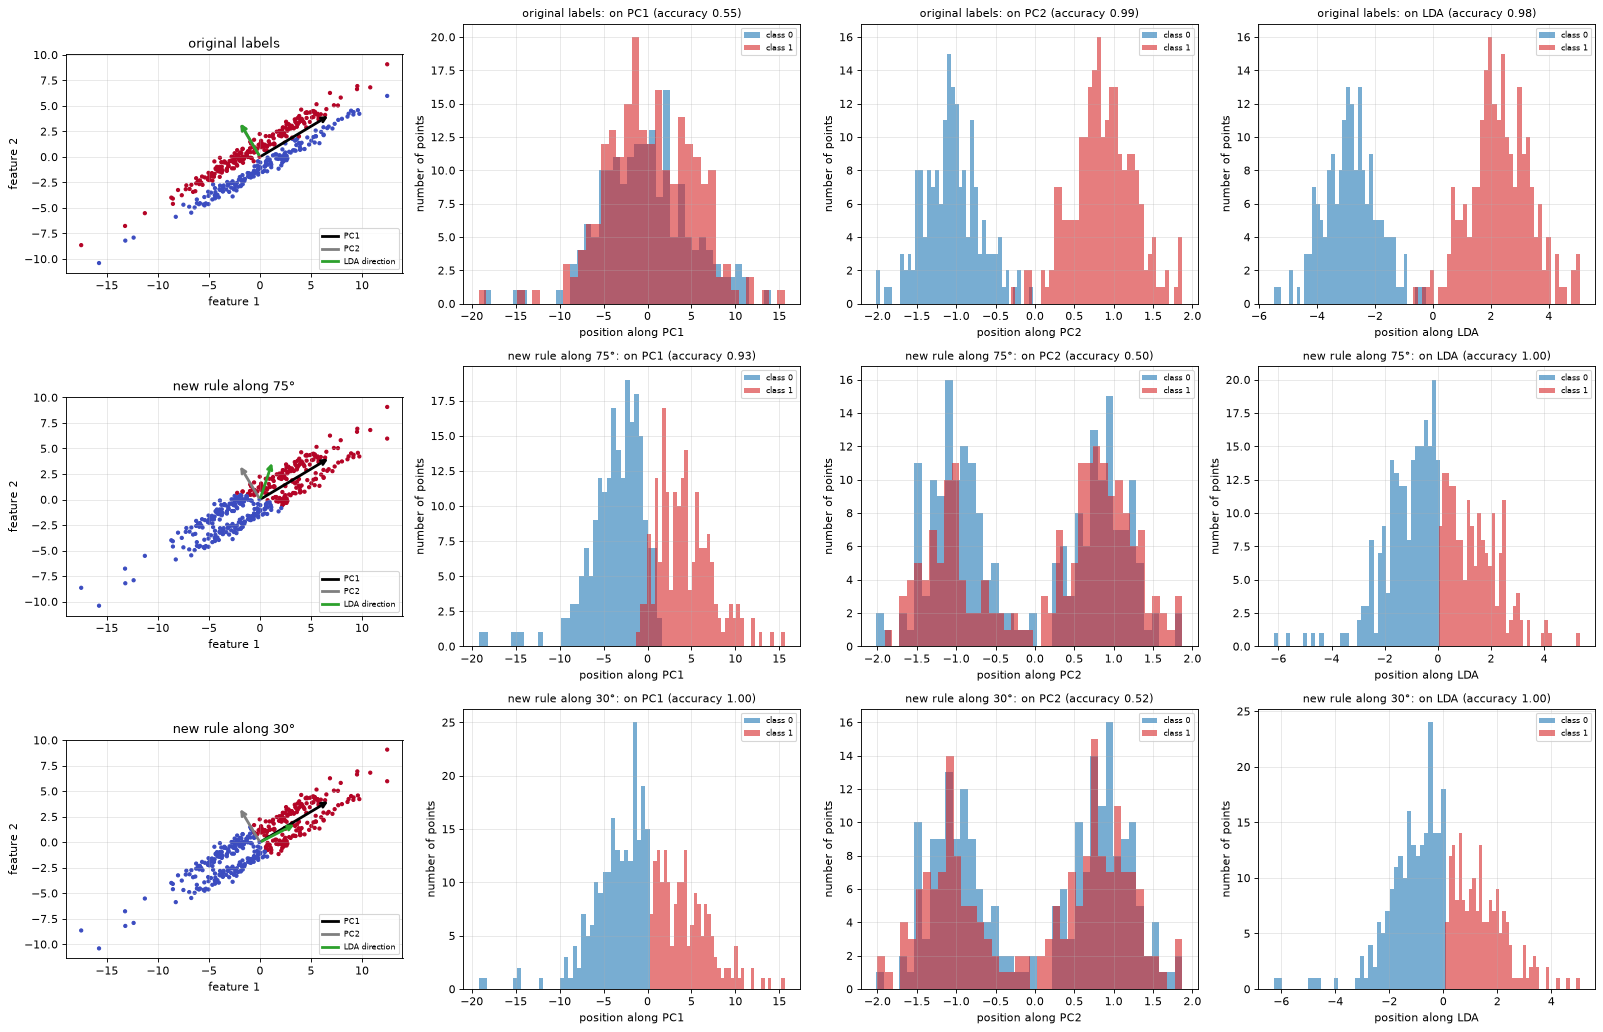

In [19]:
def accuracy_1d(feature_tr, feature_te, y_tr, y_te):
    """Test accuracy of a logistic regression trained on a single feature column."""
    return LogisticRegression().fit(feature_tr.reshape(-1, 1), y_tr).score(feature_te.reshape(-1, 1), y_te)


def labels_along(X, degrees):
    """Label a point 1 if its projection onto the direction at `degrees` is positive, else 0."""
    u = np.array([np.cos(np.radians(degrees)), np.sin(np.radians(degrees))])
    return (X @ u > 0).astype(int)


labelings = [("original labels", y12),
             ("new rule along 75°", labels_along(X12, 75)),       # <- try changing this angle
             ("new rule along 30°", labels_along(X12, 30))]

fig, axes = plt.subplots(3, 4, figsize=(20, 13))
for row, (name, y_case) in enumerate(labelings):
    X_tr, X_te, y_tr, y_te = train_test_split(X12, y_case, test_size=0.3, random_state=0)
    pca_case = PCA(n_components=2).fit(X_tr)
    lda_case = LinearDiscriminantAnalysis(n_components=1).fit(X_tr, y_tr)
    lda_dir = lda_case.scalings_[:, 0] / np.linalg.norm(lda_case.scalings_[:, 0])
    project = {"PC1": lambda X: pca_case.transform(X)[:, 0],
               "PC2": lambda X: pca_case.transform(X)[:, 1],
               "LDA": lambda X: lda_case.transform(X)[:, 0]}
    accuracy = {key: accuracy_1d(f(X_tr), f(X_te), y_tr, y_te) for key, f in project.items()}
    print(f"{name:20s}  PC1 at {angle_of(pca_case.components_[0]):5.1f}° acc {accuracy['PC1']:.2f}  |  "
          f"PC2 at {angle_of(pca_case.components_[1]):5.1f}° acc {accuracy['PC2']:.2f}  |  "
          f"LDA at {angle_of(lda_dir):5.1f}° acc {accuracy['LDA']:.2f}")

    ax = axes[row, 0]
    ax.scatter(X12[:, 0], X12[:, 1], c=y_case, cmap="coolwarm", s=8)
    draw_arrow(ax, (0, 0), 8 * pca_case.components_[0], "black", "PC1")
    draw_arrow(ax, (0, 0), 4 * pca_case.components_[1], "tab:gray", "PC2")
    draw_arrow(ax, (0, 0), 4 * lda_dir, "tab:green", "LDA direction")
    ax.set_aspect("equal"); ax.legend(fontsize=7, loc="lower right"); ax.set_title(name)
    ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2")
    for col, key in enumerate(["PC1", "PC2", "LDA"], start=1):
        z = project[key](X12)
        ax = axes[row, col]
        ax.hist(z[y_case == 0], bins=40, alpha=0.6, color="tab:blue", label="class 0")
        ax.hist(z[y_case == 1], bins=40, alpha=0.6, color="tab:red", label="class 1")
        ax.set_title(f"{name}: on {key} (accuracy {accuracy[key]:.2f})", fontsize=10)
        ax.set_xlabel(f"position along {key}"); ax.set_ylabel("number of points"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

> **How to read this**
> * **PCA's axes never move:** PC1 at 30.9° and PC2 at 120.9° in every row. PCA only sees the points, never the
>   colours. In the top row the grey PC2 arrow is hidden under the green LDA arrow (120.9° vs 120.2°).
> * **LDA follows the labels:** its direction is 120.2°, 71.8° and 27.1°, close to each rule's direction.
> * **Row 2 (rule along 75°, between the PCs):** PC1 alone gets 0.93, PC2 alone 0.50, LDA 1.00. Neither principal
>   component is the label's direction; LDA's oblique one is.
> * **Row 3 (rule along 30°, i.e. along PC1):** now PC1 is perfect (1.00) and PC2 is useless (0.52). PCA "works"
>   here only because the labels happen to line up with the biggest spread.
> * In the PC2 histograms of rows 2–3 you can still see the two humps of the *original* classes; the new colours
>   mix within each hump, so PC2 carries no information about the new labels.
> * With 2 features, keeping both PCs loses nothing. PCA's label-blindness only costs you when you **drop**
>   components, which is exactly what dimensionality reduction does.

<a id="lab-13"></a>

## Lab 13 · A few outliers can steal PC1

Variance squares distances, so a point 10× further away counts 100× more. Here 5 extreme points (2.4 % of the data)
are placed perpendicular to the real trend.

<details>
<summary><b>What does MinCovDet (robust covariance) actually do? (click to expand)</b></summary>

**In one line.** MinCovDet (Minimum Covariance Determinant, MCD) estimates the mean and covariance from the **most
tightly packed half of the data** instead of from all points, so a few far-away points cannot drag them.

**Notation.** $n$ = number of points (rows), $p$ = number of features (columns). In this lab $n = 205$, $p = 2$.

**Step 1: pick the tightest subset.** Among all subsets of $h$ points, with

$$h = \left\lceil \frac{n + p + 1}{2} \right\rceil \quad (= \lceil 208/2 \rceil = 104 \text{ here, just over half the data}),$$

find the one whose covariance matrix has the **smallest determinant**. A subset's covariance is not a number but a full
$p \times p$ matrix, computed like the ordinary covariance using only the $h$ chosen points $H$:

$$\mu_H = \frac{1}{h}\sum_{i \in H} x_i, \qquad S_H = \frac{1}{h}\sum_{i \in H} (x_i - \mu_H)(x_i - \mu_H)^\top$$

The determinant turns that matrix into one number, so subsets can be compared. "Just over half" guarantees the chosen
subset is mostly real data as long as fewer than half the points are outliers.

*Why the determinant measures the size of the cloud.* Any covariance matrix factors as $S = Q \Lambda Q^\top$ ($Q$ = the
eigenvectors, a pure rotation with determinant $\pm 1$; $\Lambda$ = the eigenvalues on the diagonal). Determinants
multiply, so $\det S = \det \Lambda = \lambda_1 \lambda_2 \cdots \lambda_p$. The standard deviation along eigenvector
$e_j$ is $\sqrt{\lambda_j}$ (Lab 3), so the one-standard-deviation ellipse has semi-axes $\sqrt{\lambda_1}, \sqrt{\lambda_2}$
and area $\pi \sqrt{\lambda_1}\sqrt{\lambda_2} = \pi \sqrt{\det S}$. So **area $\propto \sqrt{\det S}$** (volume in $p$ dimensions);
smallest determinant = smallest ellipse. Outliers stretch the ellipse, so any subset that contains them has a big
determinant. Check with Lab 1's $S = \begin{pmatrix} 2.5 & 1.5 \\ 1.5 & 2.5 \end{pmatrix}$: $\det S = 2.5^2 - 1.5^2 = 4 = 4 \times 1 = \lambda_1 \lambda_2$,
and the ellipse with semi-axes 2 and 1 has area $2\pi = \pi\sqrt{4}$.

**Step 2: find it fast (FAST-MCD).** Trying every subset is impossible, so it starts from many random small subsets and
repeats one "concentration" step: compute the subset's mean and covariance, measure every point's **Mahalanobis
distance**, keep the $h$ closest points. Each repeat can only shrink the determinant, so it converges in a few steps;
the best result over all starts wins.

**Step 3: re-weight.** With that raw estimate, points whose squared Mahalanobis distance is beyond the 97.5 % quantile
of a $\chi^2_p$ distribution (7.38 for $p = 2$) are flagged as outliers. The mean and covariance are recomputed from all
remaining points, with a correction factor so the estimate is not biased small.

**Mahalanobis distance.** For one point $x$, against a centre $\mu$ and covariance $S$:

$$d^2(x) = (x - \mu)^\top S^{-1} (x - \mu) = \sum_j \frac{\big(e_j^\top (x - \mu)\big)^2}{\lambda_j}$$

It is measured from **each point to the centre**: one number per point, not pairwise and not a sum over other points.
The right-hand form shows the intuition: rotate onto the eigen-axes and divide each coordinate by that axis's
standard deviation. Moving 2 units along the long axis counts much less than 2 units along the short axis, and all points
on the same ellipse have the same distance. scikit-learn's `mahalanobis()` returns the **squared** distance $d^2$.
For Gaussian data $d^2$ follows a $\chi^2_p$ distribution, which is where the cutoff in step 3 comes from.

**On this lab's data (205 points, 5 outliers):**

| Quantity | Value |
|---|---|
| raw subset size $h$ | 104 |
| final points kept (`support_`) | 192 |
| outliers kept | **0 of 5** |
| determinant: plain covariance, with outliers | 22.26 |
| determinant: covariance of the 200 clean points | 1.32 |
| determinant: MCD covariance | 1.09 |
| squared Mahalanobis distance: median normal point | 1.39 (median of $\chi^2_2$ = 1.386) |
| squared Mahalanobis distance: the 5 outliers | 630 – 1030 |

The lab then takes the top eigenvector of this cleaned covariance, which is why its PC1 is 40.7° instead of 124.4°.
The 192 kept points also drop a few extreme-but-genuine points, which is why the MCD determinant is slightly below the
clean data's.

**Useful attributes:** `location_` (robust mean), `covariance_`, `support_` (which points were kept),
`mahalanobis(X)` (distances, usable for outlier detection), `raw_covariance_` (before re-weighting).

**Limits:** it assumes the clean majority forms one ellipse-shaped cloud; it tolerates up to about 50 % outliers; it needs
more rows than features and gets slow beyond a few dozen features (for wide data other robust PCA methods are used).

</details>

PC1 angle, clean data           :   41.2°
PC1 angle, with 5 outliers      :  124.4°
PC1 angle, robust covariance    :   40.7°


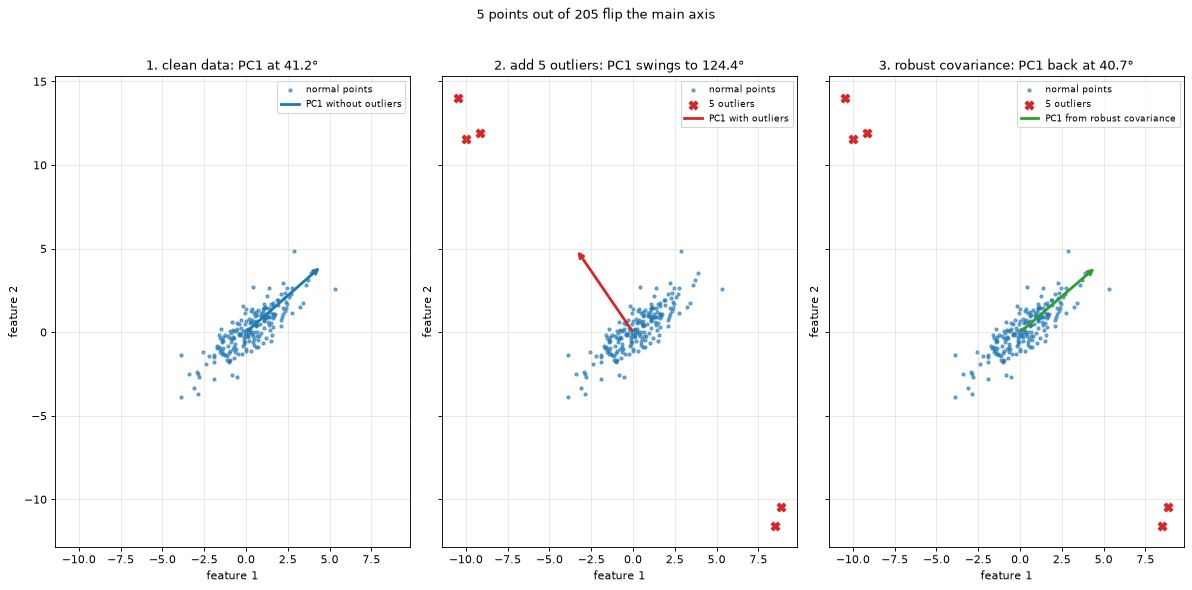

In [20]:
rng = np.random.default_rng(1)
X_clean = rng.multivariate_normal([0, 0], [[3.0, 2.0], [2.0, 2.0]], size=200)
perpendicular = np.array([-0.62, 0.79])
outliers = np.array([s * perpendicular * 15 for s in [1, 1.1, -1, -0.9, 1.05]]) + rng.normal(0, 0.5, (5, 2))
X_dirty = np.vstack([X_clean, outliers])

pc1_clean = PCA(n_components=1).fit(X_clean).components_[0]
pc1_dirty = PCA(n_components=1).fit(X_dirty).components_[0]
robust_cov = MinCovDet(random_state=0).fit(X_dirty).covariance_         # covariance that down-weights outliers
pc1_robust = np.linalg.eigh(robust_cov)[1][:, -1]
pc1_robust *= np.sign(pc1_robust @ pc1_clean)                          # u and -u are the same axis; point it the same way for the plot

print(f"PC1 angle, clean data           : {angle_of(pc1_clean):6.1f}°")
print(f"PC1 angle, with 5 outliers      : {angle_of(pc1_dirty):6.1f}°")
print(f"PC1 angle, robust covariance    : {angle_of(pc1_robust):6.1f}°")

fig, axes = plt.subplots(1, 3, figsize=(15, 7), sharex=True, sharey=True)
panels = [(axes[0], False, [(pc1_clean, "tab:blue", "PC1 without outliers")], f"1. clean data: PC1 at {angle_of(pc1_clean):.1f}°"),
          (axes[1], True, [(pc1_dirty, "tab:red", "PC1 with outliers")], f"2. add 5 outliers: PC1 swings to {angle_of(pc1_dirty):.1f}°"),
          (axes[2], True, [(pc1_robust, "tab:green", "PC1 from robust covariance")], f"3. robust covariance: PC1 back at {angle_of(pc1_robust):.1f}°")]
for ax, show_outliers, arrows, title in panels:
    ax.scatter(X_clean[:, 0], X_clean[:, 1], s=8, alpha=0.6, label="normal points")
    if show_outliers:
        ax.scatter(outliers[:, 0], outliers[:, 1], s=60, color="tab:red", marker="X", label="5 outliers")
    for vector, color, label in arrows:
        draw_arrow(ax, (0, 0), 6 * vector, color, label)
    ax.set_aspect("equal"); ax.legend(fontsize=8, loc="upper right"); ax.set_title(title)
    ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2")
plt.suptitle("5 points out of 205 flip the main axis", y=1.02)
plt.tight_layout(); plt.show()

> **How to read this**
> * Panel 1: without outliers PC1 follows the cloud (~41°). 
> * Panel 2: add 5 extreme points and PC1 swings to ~124°
>   to point **at the outliers**. PCA now describes 5 points instead of 200. this is because the outliers stretch the sample variance along their direction. their *outlierness* means variance along them is very high.
> * Panel 3: a robust covariance estimate (Minimum Covariance Determinant) ignores the extreme points and recovers the
>   original direction. In practice: look for and handle outliers *before* PCA, or use a robust variant.

<a id="lab-14"></a>

## Lab 14 · Nothing to compress: uncorrelated features

PCA compresses by exploiting **redundancy** (correlation). If every feature carries its own independent
information, every direction has the same spread and there is no “short list” of important directions.

A second case checks a loophole: features that are uncorrelated but have **unequal** spreads.

independent features                         : 2 components keep 24%, components for 95% = 10
10 features from 2 hidden causes             : 2 components keep 98%, components for 95% = 2
independent, unequal spreads (raw)           : 2 components keep 95%, components for 95% = 3
independent, unequal spreads (standardised)  : 2 components keep 24%, components for 95% = 10

unequal spreads, raw:  PC1 = [ 1.    0.02  0.    0.    0.    0.   -0.   -0.   -0.    0.01]
                       PC2 = [-0.02  1.    0.    0.01  0.    0.   -0.02  0.01 -0.   -0.01]


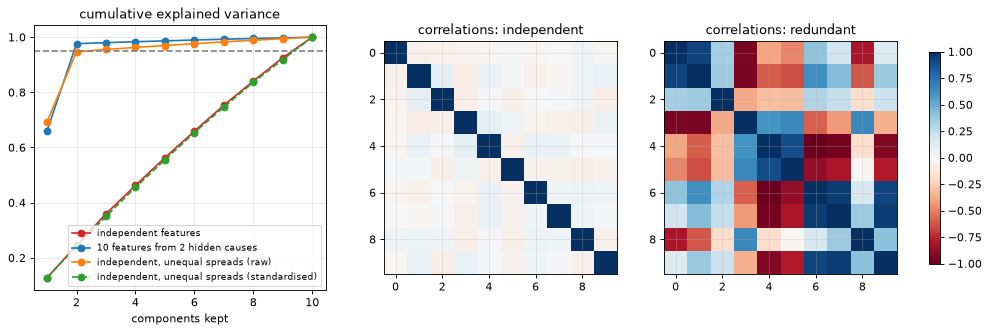

In [21]:
rng = np.random.default_rng(0)
n_samples, n_features = 500, 10
X_independent = rng.normal(size=(n_samples, n_features))                 # 10 unrelated features
hidden_factors = rng.normal(size=(n_samples, 2))                         # 2 hidden causes...
X_redundant = hidden_factors @ rng.normal(size=(2, n_features)) + 0.2 * rng.normal(size=(n_samples, n_features))  # ...drive 10 features
spreads = np.array([10, 6, 1, 1, 1, 1, 1, 1, 1, 1])                       # <- try changing this
X_unequal = rng.normal(size=(n_samples, n_features)) * spreads            # 10 unrelated features, 2 of them much wider
X_unequal_scaled = StandardScaler().fit_transform(X_unequal)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
cases = [(X_independent, "independent features", "tab:red"),
         (X_redundant, "10 features from 2 hidden causes", "tab:blue"),
         (X_unequal, "independent, unequal spreads (raw)", "tab:orange"),
         (X_unequal_scaled, "independent, unequal spreads (standardised)", "tab:green")]
for X_case, label, color in cases:
    cum = np.cumsum(PCA().fit(X_case).explained_variance_ratio_)
    axes[0].plot(range(1, n_features + 1), cum, marker="o", color=color, label=label,
                 ls="--" if "standardised" in label else "-")
    print(f"{label:45s}: 2 components keep {cum[1]:.0%}, components for 95% = {np.searchsorted(cum, 0.95) + 1}")
pca_unequal = PCA().fit(X_unequal)
print("\nunequal spreads, raw:  PC1 =", pca_unequal.components_[0].round(2))
print("                       PC2 =", pca_unequal.components_[1].round(2))
axes[0].axhline(0.95, color="gray", ls="--"); axes[0].set_xlabel("components kept"); axes[0].legend(fontsize=8)
axes[0].set_title("cumulative explained variance")
for ax, X_case, title in [(axes[1], X_independent, "correlations: independent"), (axes[2], X_redundant, "correlations: redundant")]:
    image = ax.imshow(np.corrcoef(X_case.T), cmap="RdBu", vmin=-1, vmax=1); ax.set_title(title)
plt.colorbar(image, ax=axes[1:], shrink=0.8)
plt.show()

> **How to read this**
> * Redundant data (blue): 2 components already keep ~98 % — PCA found the 2 hidden causes.
> * Independent data (red): the curve is almost a straight diagonal; you need all 10 of 10 components for 95 %.
>   PCA would just rotate the data for nothing.
> * Unequal spreads, raw (orange): 2 components keep ~95 % although nothing is correlated. But the printed PC1 and
>   PC2 are just feature 1 and feature 2: PCA simply kept the two widest columns, which needs no PCA. That is a
>   scale effect (like Lab 10), not compression.
> * The same data standardised (green): back to the straight diagonal, 10 of 10 components. **On standardised
>   data, only correlation lets PCA compress.**
> * The correlation heat-maps tell you in advance (for standardised data; correlation ignores scale): lots of strong red/blue off the diagonal → PCA will help;
>   a nearly white matrix → it will not. (This is the README's “almost all components needed for 90 %” failure.)

<a id="lab-15"></a>

## Lab 15 · Uncorrelated is not the same as un-mixed (PCA vs ICA)

Two microphones record two people talking at once; each recording is a **mix** of both voices. PCA makes its
outputs *uncorrelated*, but that is a weaker property than *independent*, so it generally does **not**
recover the original voices. Independent Component Analysis (ICA) is built for this.

**What goes in**

* **True source 1:** a smooth sine wave, $s_1(t) = \sin(2t)$, one "voice" (about 2.5 slow cycles over the plot).
* **True source 2:** a saw-tooth wave, $s_2(t) = 2\,\mathrm{frac}(1.5t) - 1$: it rises in a straight line from −1 to +1,
  then drops back instantly, 12 times over the plot. The other "voice".
* **The mixing matrix** $A = \begin{pmatrix} 1 & 1 \\ 0.5 & 2 \end{pmatrix}$ models how the two voices reach the two
  microphones. Each **row** is a microphone and each **column** a source: microphone 1 $= 1\cdot s_1 + 1\cdot s_2$
  (equally close to both speakers), microphone 2 $= 0.5\cdot s_1 + 2\cdot s_2$ (much closer to speaker 2). In code,
  `X_mixed = sources @ mixing.T` is $x(t) = A\,s(t)$ at every time step. PCA and ICA only see the two microphone
  recordings, never $A$ or the sources.

<details>
<summary><b>What does ICA do, and how is FastICA different from ICA? (click to expand)</b></summary>

**The goal.** Find an **un-mixing** matrix $W$ so that $\hat s(t) = W\,x(t)$ gives back the sources, i.e. $W \approx A^{-1}$.
The order of the outputs and their sign/scale cannot be recovered (swapping two speakers, or turning one's volume up
while dividing its column of $A$ by the same amount, gives exactly the same recordings).

**The assumption.** The sources are **statistically independent** and **non-Gaussian** (at most one may be Gaussian).

**Why non-Gaussian is the key.** By the central limit theorem, a mix of independent signals looks *more Gaussian*
(more bell-shaped) than each ingredient on its own. So turning the un-mixing knob until each output is as
**non-Gaussian as possible** undoes the mixing.

**The steps.**
1. **Centre** each microphone signal (subtract its mean).
2. **Whiten:** run PCA and rescale each component to variance 1 (`whiten="unit-variance"` in the code). The outputs
   are now uncorrelated with equal spread. **This is where PCA stops.** After whitening the cloud is a circle, and every
   rotation of a circle is still a circle, so variances and covariances can no longer tell which rotation is right. That
   is why PCA's outputs here are uncorrelated but still mixed.
3. **Rotate:** search for the rotation that makes each output as non-Gaussian as possible. Non-Gaussianity is measured
   with *kurtosis* (how peaked or flat the histogram is) or, more robustly, an approximation of *negentropy*.

**ICA vs FastICA.** ICA is the **problem** (the model $x = A s$ with independent, non-Gaussian $s$); FastICA is one
**algorithm** for solving it (Hyvärinen & Oja, 1999). Instead of slow gradient steps with a learning rate, it updates each
un-mixing direction $w$ with a fixed-point rule,

$$w \leftarrow \mathbb{E}\big[x\, g(w^\top x)\big] - \mathbb{E}\big[g'(w^\top x)\big]\, w, \qquad \text{then rescale } w \text{ to length 1,}$$

where $g = \tanh$ (scikit-learn's default `fun="logcosh"`), and keeps the directions perpendicular to each other. It
typically converges in a handful of iterations. Other ICA algorithms (Infomax, JADE, Picard) solve the same problem
differently; scikit-learn ships only FastICA.

</details>

how well each true source is recovered (1.0 = perfect)
  PCA: [0.887 0.882]
  ICA: [1. 1.]


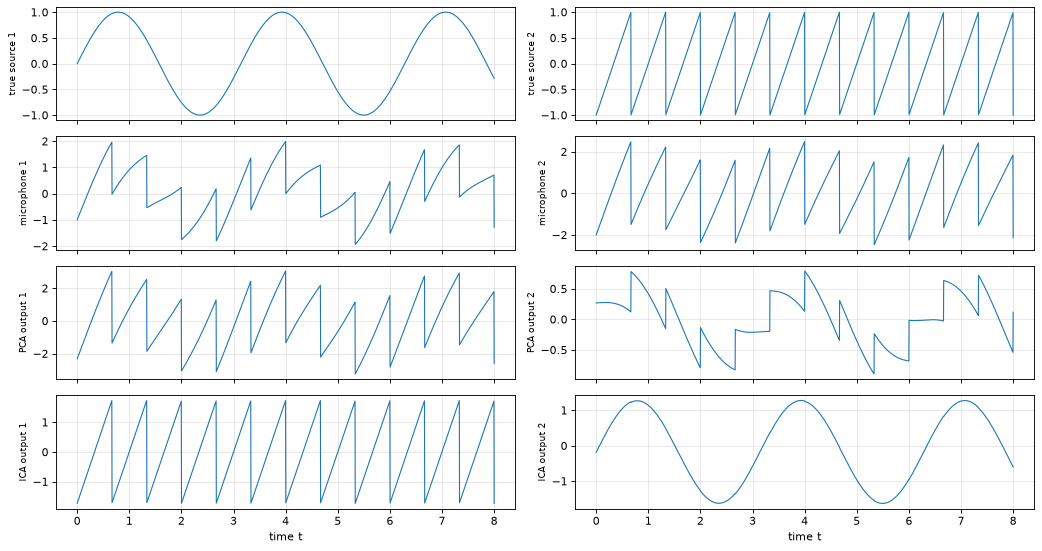

In [22]:
t = np.linspace(0, 8, 2000)
sources = np.column_stack([np.sin(2 * t),                 # source 1: smooth wave
                           2 * ((1.5 * t) % 1) - 1])      # source 2: saw-tooth
mixing = np.array([[1.0, 1.0], [0.5, 2.0]])                # each 'microphone' hears both sources
X_mixed = sources @ mixing.T

pca_out = PCA(n_components=2).fit_transform(X_mixed)
ica_out = FastICA(n_components=2, whiten="unit-variance", random_state=0).fit_transform(X_mixed)


def best_match(recovered):
    """For each true source, the highest |correlation| with any recovered signal (1.0 = perfectly recovered)."""
    corr = np.abs(np.corrcoef(sources.T, recovered.T)[:2, 2:])
    return corr.max(axis=1)


print("how well each true source is recovered (1.0 = perfect)")
print("  PCA:", best_match(pca_out))
print("  ICA:", best_match(ica_out))

fig, axes = plt.subplots(4, 2, figsize=(13, 7), sharex=True)
for col in range(2):
    for row, (signals, name) in enumerate([(sources, "true source"), (X_mixed, "microphone"), (pca_out, "PCA output"), (ica_out, "ICA output")]):
        axes[row, col].plot(t, signals[:, col], lw=1)
        axes[row, col].set_ylabel(f"{name} {col+1}", fontsize=8)
    axes[-1, col].set_xlabel("time t")
plt.tight_layout(); plt.show()

> **How to read this**
> * Row 1 is the truth (a wave and a saw-tooth), row 2 is what the microphones recorded (mixes).
> * PCA's outputs (row 3) are uncorrelated, but each still clearly contains a bit of both shapes.
> * ICA's outputs (row 4) are a clean wave and a clean saw-tooth (possibly flipped or re-ordered — ICA, like PCA,
>   cannot know the sign or the order).
> * Why: PCA only uses **variances and covariances** (2nd-order statistics). Those are fully described by an
>   ellipse, and many different rotations give the same ellipse. ICA uses the *shape* of the distributions beyond the
>   ellipse to pick the one rotation that un-mixes them.

---

<a id="part-d"></a>

# Part D — Does PCA help this model?

The model guide at the end of the notebook makes claims about which models PCA helps. These two labs test one
"no" and one "yes":

| Lab | Claim from the model guide | Result |
|---|---|---|
| 16 | Tree models (random forest, gradient boosting) don't want PCA | mostly no: rotation ties or hurts |
| 17 | Clustering on noisy, high-dimensional data does | mostly yes: big gains with noise and for Gaussian mixtures |

<a id="lab-16"></a>

## Lab 16 · Trees after PCA: blended columns make worse splits

**Goal:** test the claim from the model guide at the end: *trees split on one column at a time, so blended PC
columns usually make worse splits.*

**The fair test.** Both versions standardise the data. One version then applies `PCA()` with **all** components
kept, so it has exactly the same information, only seen along rotated axes. Any change in the score comes from the
rotation alone, not from dropping components.

1. A 2-D picture of *why*: a rule that is one clean cut on an original column becomes a slanted line after PCA.
   The dashed line is the true rule; the shaded regions are what the tree learned.
2. The same test on scikit-learn's toy datasets: iris, wine and breast_cancer (classification), California housing
   and diabetes (regression). California housing is downloaded once (about 400 KB) and then cached in
   `~/scikit_learn_data`. Linnerud is left out: with only 20 rows, no model predicts it (R² far below 0).

original columns    : depth-4 accuracy 1.000, leaves needed to fit the training data perfectly: 2
PCA-rotated columns : depth-4 accuracy 0.940, leaves needed to fit the training data perfectly: 16


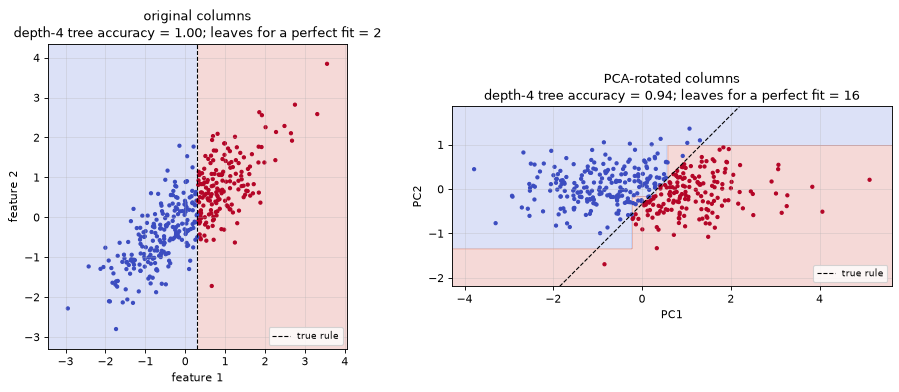

In [23]:
rng = np.random.default_rng(0)
X_toy = rng.multivariate_normal([0, 0], [[1.0, 0.8], [0.8, 1.0]], size=400)   # two correlated features
y_toy = (X_toy[:, 0] > 0.3).astype(int)                                        # label = one clean cut on feature 1
rotate = make_pipeline(StandardScaler(), PCA()).fit(X_toy)
Z_toy = rotate.transform(X_toy)                                                # same points, rotated axes
true_cut = np.array([[0.3, -4.0], [0.3, 4.0]])                                 # two points on the line "feature 1 = 0.3"

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, F, cut, title, (xl, yl) in [(axes[0], X_toy, true_cut, "original columns", ("feature 1", "feature 2")),
                                   (axes[1], Z_toy, rotate.transform(true_cut), "PCA-rotated columns", ("PC1", "PC2"))]:
    shallow = DecisionTreeClassifier(max_depth=4, random_state=0)               # <- try changing max_depth
    accuracy = cross_val_score(shallow, F, y_toy, cv=cv5).mean()
    leaves = DecisionTreeClassifier(random_state=0).fit(F, y_toy).get_n_leaves()
    shallow.fit(F, y_toy)
    g1, g2 = np.meshgrid(np.linspace(F[:, 0].min() - 0.5, F[:, 0].max() + 0.5, 300),
                         np.linspace(F[:, 1].min() - 0.5, F[:, 1].max() + 0.5, 300))
    regions = shallow.predict(np.c_[g1.ravel(), g2.ravel()]).reshape(g1.shape)
    ax.contourf(g1, g2, regions, alpha=0.2, cmap="coolwarm")
    ax.scatter(F[:, 0], F[:, 1], c=y_toy, s=8, cmap="coolwarm")
    ax.axline(cut[0], cut[1], color="black", ls="--", lw=1, label="true rule")
    ax.set_xlim(F[:, 0].min() - 0.5, F[:, 0].max() + 0.5); ax.set_ylim(F[:, 1].min() - 0.5, F[:, 1].max() + 0.5)
    ax.set_xlabel(xl); ax.set_ylabel(yl); ax.set_aspect("equal"); ax.legend(loc="lower right", fontsize=8)
    ax.set_title(f"{title}\ndepth-4 tree accuracy = {accuracy:.2f}; leaves for a perfect fit = {leaves}")
    print(f"{title:20s}: depth-4 accuracy {accuracy:.3f}, leaves needed to fit the training data perfectly: {leaves}")
plt.tight_layout(); plt.show()

In [24]:
cv_class = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
cv_reg = KFold(n_splits=5, shuffle=True, random_state=0)
X_house, y_house = fetch_california_housing(return_X_y=True)        # downloaded once, then cached
keep = np.random.default_rng(0).choice(len(X_house), 4000, replace=False)   # 4 000 of 20 640 rows, to keep it fast
X_house, y_house = X_house[keep], y_house[keep]
forest_c, boost_c = RandomForestClassifier(n_estimators=100, random_state=0), GradientBoostingClassifier(random_state=0)
forest_r, boost_r = RandomForestRegressor(n_estimators=100, random_state=0), GradientBoostingRegressor(random_state=0)

experiments = [
    ("iris (classification)", *load_iris(return_X_y=True), "accuracy", cv_class, [forest_c, boost_c]),
    ("wine (classification)", *load_wine(return_X_y=True), "accuracy", cv_class, [forest_c, boost_c]),
    ("breast_cancer (classification)", *load_breast_cancer(return_X_y=True), "accuracy", cv_class, [forest_c, boost_c]),
    ("california housing (regression)", X_house, y_house, "r2", cv_reg, [forest_r, boost_r]),
    ("diabetes (regression)", *load_diabetes(return_X_y=True), "r2", cv_reg, [forest_r, boost_r]),
]
add_pcs = make_union(FunctionTransformer(), PCA())       # original columns AND all PC columns side by side

print(f"{'dataset':33s} {'model':26s} {'metric':8s} {'original':>8s} {'rotated':>8s} {'change':>7s} {'orig+PCs':>8s}")
for name, X, y, metric, cv, models in experiments:
    for model in models:
        original = cross_val_score(make_pipeline(StandardScaler(), model), X, y, cv=cv, scoring=metric).mean()
        rotated = cross_val_score(make_pipeline(StandardScaler(), PCA(), model), X, y, cv=cv, scoring=metric).mean()
        both = cross_val_score(make_pipeline(StandardScaler(), add_pcs, model), X, y, cv=cv, scoring=metric).mean()
        print(f"{name:33s} {type(model).__name__:26s} {metric:8s} {original:8.3f} {rotated:8.3f} {rotated - original:+7.3f} {both:8.3f}")

dataset                           model                      metric   original  rotated  change orig+PCs


iris (classification)             RandomForestClassifier     accuracy    0.940    0.927  -0.013    0.933


iris (classification)             GradientBoostingClassifier accuracy    0.927    0.927  +0.000    0.927


wine (classification)             RandomForestClassifier     accuracy    0.972    0.972  +0.000    0.977


wine (classification)             GradientBoostingClassifier accuracy    0.949    0.933  -0.017    0.933


...

breast_cancer (classification)    GradientBoostingClassifier accuracy    0.965    0.949  -0.016    0.970


california housing (regression)   RandomForestRegressor      r2          0.763    0.682  -0.081    0.756


california housing (regression)   GradientBoostingRegressor  r2          0.766    0.677  -0.089    0.760


diabetes (regression)             RandomForestRegressor      r2          0.418    0.444  +0.026    0.448


diabetes (regression)             GradientBoostingRegressor  r2          0.421    0.436  +0.015    0.409


> **How to read this**
> * Picture: on the original columns the label is one vertical cut, so the tree is perfect and a full tree needs
>   just 2 leaves. After PCA the same cut is the slanted dashed line. Trees can only cut parallel to an axis, so they
>   approximate it with a staircase: even at depth 4 the tree only reaches about 0.94, and a perfect fit needs
>   16 leaves. More cuts on less data per leaf means worse generalisation.
> * Table, `rotated` vs `original`, classification: on iris, wine and breast_cancer the rotation costs a little
>   accuracy or ties. These are easy problems where many splits work, so the damage is small.
> * Regression: California housing loses clearly (R² 0.76 → 0.68 for both models). Its columns (income, house age,
>   location, …) each matter on their own, so blending them hurts.
> * **Not always:** on diabetes the rotation *helps* slightly. Its target depends on combinations of correlated
>   columns, so a blended column can be a better thing to split on. That is why the claim says *usually*.
> * `orig+PCs` keeps the original columns and adds the PCs as extra ones: the trees then use whichever splits work.
>   It lands close to the original everywhere and sometimes beats it (breast_cancer gradient boosting 0.970, wine
>   random forest 0.977). It is the safer way to try PCA with trees; keep it only if cross-validation says it helps.

<a id="lab-17"></a>

## Lab 17 · PCA before clustering: when does it help?

**Goal:** test the model guide's claim that PCA helps clustering on high-dimensional data. \
Clustering never sees the labels; we use the true labels **only to score** the result with the **Adjusted Rand Index (ARI)**: 
   - 1 = the clusters match, the true groups perfectly, 
   - 0 = no better than random.

1. **The mechanism, on synthetic data:** 5 real groups living in 5 columns, buried under more and more useless noise
   columns. Watch distances stop meaning anything, and see whether 5 PCs rescue the clustering.
2. **Real high-dimensional data:** digits (64 pixel columns) and the Olivetti faces (400 photos of 40 people,
   4096 pixel columns, far more columns than rows). The faces are downloaded once (about 1.4 MB) and cached in
   `~/scikit_learn_data`.

Three clustering methods are compared: k-means (distances to centres), agglomerative (distances between points)
and a Gaussian mixture (one covariance matrix per cluster).

    0 noise columns | distance contrast 29.88 | ARI raw: k-means 0.98  agglomerative 0.96  Gaussian mixture 0.97 | ARI on 5 PCs: k-means 0.98  agglomerative 0.96  Gaussian mixture 0.97
  100 noise columns | distance contrast  0.99 | ARI raw: k-means 0.95  agglomerative 0.68  Gaussian mixture 0.64 | ARI on 5 PCs: k-means 0.94  agglomerative 0.89  Gaussian mixture 0.93
  300 noise columns | distance contrast  0.42 | ARI raw: k-means 0.84  agglomerative 0.54  Gaussian mixture 0.49 | ARI on 5 PCs: k-means 0.90  agglomerative 0.84  Gaussian mixture 0.89


 1000 noise columns | distance contrast  0.21 | ARI raw: k-means 0.33  agglomerative 0.21  Gaussian mixture 0.14 | ARI on 5 PCs: k-means 0.69  agglomerative 0.61  Gaussian mixture 0.65


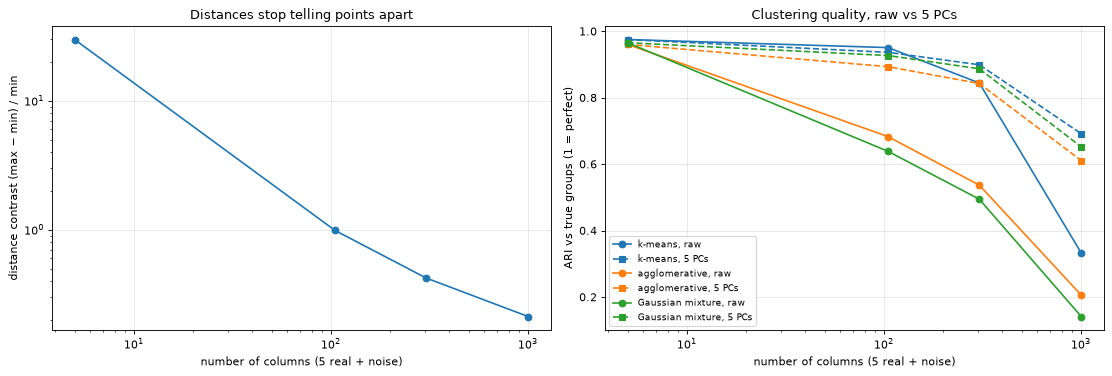

In [25]:
rng = np.random.default_rng(0)
X_signal, y_blobs = make_blobs(n_samples=500, n_features=5, centers=5, cluster_std=3.0, random_state=1)  # 5 real columns
noise_counts = [0, 100, 300, 1000]                                       # <- try changing this
clusterers = {"k-means": lambda Z, k: KMeans(k, n_init=10, random_state=0).fit_predict(Z),
              "agglomerative": lambda Z, k: AgglomerativeClustering(k).fit_predict(Z),
              "Gaussian mixture": lambda Z, k: GaussianMixture(k, random_state=0).fit(Z).predict(Z)}

contrast, ari = [], {(name, kind): [] for name in clusterers for kind in ("raw", "PCA")}
for n_noise in noise_counts:
    X_case = np.hstack([X_signal, rng.normal(0, 3.0, (500, n_noise))])   # add useless noise columns
    distances = pdist(X_case)                                             # all pairwise distances
    contrast.append((distances.max() - distances.min()) / distances.min())
    Z_case = PCA(n_components=5, random_state=0).fit_transform(X_case) if n_noise else X_case
    for name, cluster in clusterers.items():
        ari[(name, "raw")].append(adjusted_rand_score(y_blobs, cluster(X_case, 5)))
        ari[(name, "PCA")].append(adjusted_rand_score(y_blobs, cluster(Z_case, 5)))
    print(f"{n_noise:5d} noise columns | distance contrast {contrast[-1]:5.2f} | ARI raw: "
          + "  ".join(f"{name} {ari[(name, 'raw')][-1]:.2f}" for name in clusterers)
          + " | ARI on 5 PCs: " + "  ".join(f"{name} {ari[(name, 'PCA')][-1]:.2f}" for name in clusterers))

total_columns = [5 + n for n in noise_counts]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].plot(total_columns, contrast, marker="o")
axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].set_xlabel("number of columns (5 real + noise)")
axes[0].set_ylabel("distance contrast (max − min) / min"); axes[0].set_title("Distances stop telling points apart")
for name, color in zip(clusterers, ["tab:blue", "tab:orange", "tab:green"]):
    axes[1].plot(total_columns, ari[(name, "raw")], marker="o", color=color, label=f"{name}, raw")
    axes[1].plot(total_columns, ari[(name, "PCA")], marker="s", ls="--", color=color, label=f"{name}, 5 PCs")
axes[1].set_xscale("log"); axes[1].set_xlabel("number of columns (5 real + noise)")
axes[1].set_ylabel("ARI vs true groups (1 = perfect)"); axes[1].set_title("Clustering quality, raw vs 5 PCs")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

> **How to read this (synthetic blobs + noise columns)**
> * **Left:** with only the 5 real columns, the farthest pair of points is about 30× farther apart than the nearest pair
>   (contrast 29.88). With 1000 noise columns added it collapses to 0.21: every point is roughly equally far from every
>   other, so "close" stops meaning "similar". This is the curse of dimensionality.
> * **Right:** raw clustering falls apart as the noise grows (k-means 0.98 → 0.33, Gaussian mixture 0.97 → 0.14). On
>   5 PCs it holds up much better (0.69 and 0.65). PCA finds the 5 real columns because their cluster gaps give them most
>   of the variance, and it drops the noise. It is not perfect at 1000 noise columns: some noise leaks into the top PCs.

In [26]:
faces = fetch_olivetti_faces()                                          # downloaded once, then cached
X_faces, y_faces = faces.data, faces.target

real_cases = [("digits (64 columns)", X_digits, y_digits, 20),            # <- try changing the number of PCs
              ("Olivetti faces (4096 columns)", X_faces, y_faces, 50)]
print(f"{'dataset':30s} {'method':17s} {'ARI raw':>8s} {'time raw':>9s} {'ARI PCA':>8s} {'time PCA':>9s}")
for name, X_case, y_case, n_pcs in real_cases:
    k = len(np.unique(y_case))
    Z_case = PCA(n_components=n_pcs, random_state=0).fit_transform(X_case)
    for method, cluster in clusterers.items():
        gmm_bytes = k * X_case.shape[1] ** 2 * 8                           # k full covariance matrices of p x p numbers
        if method == "Gaussian mixture" and gmm_bytes > 1e9:
            raw_text = f"{'skipped':>8s} {'':>9s}"                          # needs too much memory on raw pixels
        else:
            start = time.perf_counter(); raw = adjusted_rand_score(y_case, cluster(X_case, k)); raw_time = time.perf_counter() - start
            raw_text = f"{raw:8.3f} {raw_time:8.2f}s"
        start = time.perf_counter(); reduced = adjusted_rand_score(y_case, cluster(Z_case, k)); reduced_time = time.perf_counter() - start
        print(f"{name:30s} {method:17s} {raw_text} {reduced:8.3f} {reduced_time:8.2f}s")
print(f"\nGaussian mixture on raw faces would need 40 covariance matrices of 4096 x 4096 numbers ≈ {40 * 4096**2 * 8 / 1e9:.1f} GB")

dataset                        method             ARI raw  time raw  ARI PCA  time PCA
digits (64 columns)            k-means              0.666     0.04s    0.668     0.04s
digits (64 columns)            agglomerative        0.794     0.03s    0.783     0.02s


digits (64 columns)            Gaussian mixture     0.611     0.08s    0.842     0.03s


Olivetti faces (4096 columns)  k-means              0.406     0.48s    0.478     0.03s
Olivetti faces (4096 columns)  agglomerative        0.491     0.07s    0.516     0.00s
Olivetti faces (4096 columns)  Gaussian mixture   skipped              0.455     0.01s

Gaussian mixture on raw faces would need 40 covariance matrices of 4096 x 4096 numbers ≈ 5.4 GB


> **How to read this (real data: digits and faces)**
> * Real data is more mixed than the synthetic case.
> * **Digits:** k-means barely changes (0.666 → 0.668) and agglomerative dips slightly (0.794 → 0.783), but the
>   Gaussian mixture jumps (0.611 → 0.842). It estimates a 64 × 64 covariance matrix per cluster from about 180 points
>   each, and PCA makes that estimate stable.
> * **Faces:** k-means 0.406 → 0.478, agglomerative 0.491 → 0.516, and the Gaussian mixture is only possible after PCA
>   (on raw pixels it would need ≈ 5.4 GB). Everything also runs much faster (time columns; the exact seconds depend
>   on your machine).
> * **Lesson:** PCA helps clustering most when there are many noisy or redundant columns, and for methods that estimate
>   covariances. On moderate, clean data (digits with k-means) it mostly buys speed. The number of PCs is a knob: 5, 20
>   and 50 were picked by hand here, so try a few.

---

<a id="summary"></a>

# Summary — what each lab showed

| Lab | Claim from the README | Verdict |
|---|---|---|
| [1](#lab-1) | The hand-worked example: λ = 4 and 1, 80 % / 20 % | ✔ same numbers |
| [2](#lab-2) | Eigenvectors are the directions a matrix only stretches | ✔ turn = 0 only there |
| [3](#lab-3) | Max projected variance = min reconstruction error = top eigenvector | ✔ brute force agrees |
| [4](#lab-4) | eig(covariance) = SVD = sklearn; PC scores are uncorrelated | ✔ |
| [5](#lab-5) | A few components hold most of the variance (digits: ~29 of 64 for 95 %) | ✔ |
| [6](#lab-6) | Components are pixel patterns; 2 PCs already give a useful map | ✔ |
| [7](#lab-7) | Reconstruction error = sum of dropped eigenvalues | ✔ exactly |
| [8](#lab-8) | Dropping small components removes noise | ✔ U-shaped error |
| [9](#lab-9) | Fewer features, (almost) same accuracy | ✔ plateau |
| [10](#lab-10) | ✘ Different units → biggest unit wins; standardise | failure shown |
| [11](#lab-11) | ✘ Curved structure → linear PCA can't unfold it | failure shown |
| [12](#lab-12) | ✘ Big variance ≠ label information | failure shown |
| [13](#lab-13) | ✘ Outliers hijack the components | failure shown |
| [14](#lab-14) | ✘ No correlation → no compression (unequal spreads only mimic it, until you standardise) | failure shown |
| [15](#lab-15) | ✘ Uncorrelated ≠ independent (use ICA for un-mixing) | failure shown |
| [16](#lab-16) | ✘ Trees split one column at a time; PCA-blended columns usually make worse splits | failure shown (diabetes is the exception) |
| [17](#lab-17) | PCA before clustering helps on noisy, high-dimensional data | ✔ big gain with noise columns and for Gaussian mixtures; small or none for k-means on digits |


---

<a id="beyond-the-labs"></a>

# Beyond the labs: which models does PCA help?

The labs show what PCA does to the *data*. Whether it helps depends just as much on the *model* you feed the
components to. This guide is for high-dimensional data (hundreds to thousands of columns).

**PCA usually helps**

| Model | Why |
|---|---|
| **k-NN, k-means and other clustering, any distance-based method**<br><span style="color:#0fa3b1">Clustering: k-means, hierarchical / agglomerative, Gaussian mixtures (GMM), DBSCAN / HDBSCAN, spectral and graph-based (Leiden / Louvain)</span> | In many dimensions, distances between points become nearly equal, and noisy columns swamp the useful ones. Reducing to the top ~20–100 PCs makes distances meaningful again. This is standard practice: single-cell RNA-seq, for example, runs PCA to 50 dimensions before clustering. Lab 17 tests this. |
| **t-SNE / UMAP visualisation** | Reducing to ~50 PCs first is the standard recipe. It removes noise and makes them much faster. |
| **Linear / logistic regression when there are more columns than rows** (e.g. 20 000 genes, 200 patients) | Plain least squares has no unique solution when p > n. Regressing on the top k PCs makes it solvable and stable. |
| **LDA, QDA, Gaussian mixtures, Gaussian processes** | These estimate a p × p covariance matrix, about p²/2 numbers, which needs far more rows than p. PCA shrinks p so that estimate becomes possible. |
| **SVM with RBF kernel** | Kernel cost grows with p, and noisy dimensions hurt it. Fewer, cleaner features make it faster and often more accurate. |
| **Compressing dense embeddings for search** (e.g. 1536 → 256 dimensions) | Storage and nearest-neighbour search get much cheaper at a small cost in quality. |

**PCA usually hurts or isn't needed**

| Model / data | Why |
|---|---|
| **Gradient boosting, XGBoost, random forest** | Trees split on one column at a time, so blended PC columns usually make worse splits. Correlated columns don't hurt their accuracy, they ignore scale, and they already cope with thousands of columns by sampling columns and picking good splits. Lab 16 tests this. |
| **CNNs on images, transformers on text or sequences** | PCA treats the input as a flat list and throws away structure: which pixels are neighbours, and word order. Those models exist to exploit exactly that structure and learn better features themselves, given enough data. |
| **Sparse data: TF-IDF text, one-hot columns** | PCA subtracts the mean first, which turns a mostly-zero matrix dense and can make memory explode. Use `TruncatedSVD` (latent semantic analysis) instead, or just a linear model, which handles sparse data well. |
| **When there's a better supervised option: lasso, elastic net, PLS** | PCA ignores the target. Lasso picks the useful original columns, and PLS picks directions that predict y. Either often beats PCA's unsupervised choice. |
| **When the signal sits in a low-variance direction** | PCA keeps big variance, not usefulness. In Lab 12, PC1 alone gave 0.55 accuracy and PC2 gave 0.99. |
| **When interpretability or regulation matters** | Decisions based on “PC7” can't be explained. Feature selection keeps real column names. |

**Rule of thumb**

* PCA helps models that **treat the input as a plain vector and suffer when p is large relative to n**:
  distance-based methods, covariance estimation and plain linear fits.
* It hurts or adds little for models that **choose features themselves** (trees, lasso), **exploit structure in the
  raw input** (CNNs, sequence models) or **rely on sparsity**.
* Either way, PCA picks directions by variance, not by how well they predict, so choose k by cross-validation
  inside a `Pipeline` (as in Lab 9) rather than by an explained-variance threshold alone.